# Weather Intelligence: preprocessing

Builds model-ready training, validation and test datasets for **both** prediction tasks in
UTS 36120 Advanced ML, Assessment Task 2.

**Student:** 25945320

| Target | Type | Horizon | Output |
| --- | --- | --- | --- |
| Climate Comfort Index (CCI) | Regression | +1, +2, +3 days | `data/processed/comfort_climate/` |
| Weather Hazard Category (WHC) | Multiclass classification | exactly +7 days | `data/processed/weather_hazard/` |

Pipeline: hourly Sydney archive -> daily aggregation -> CCI and WHI/WHC calculation -> one
shared leakage-safe feature matrix -> per-target alignment -> per-target chronological split
with an embargo.

**Why one notebook.** Both targets are derived from the same hourly archive, at the same
location, aggregated the same way, and are predicted from the same information set: everything
observed on or before day *t*. Only the label column and the forecast horizon differ. Building
the feature matrix once and branching at the target step removes the risk of the two pipelines
drifting apart, halves the code the API has to reproduce at inference time, and lets the
comfort and hazard models be compared on an identical information set.

**What differs between the two tasks**

| Step | Shared? | Notes |
| --- | --- | --- |
| Daily aggregation | Shared | One aggregation rule per variable, section 1 |
| Feature matrix `X` | Shared | Identical columns for both tasks, section 3 |
| Target `y` | **Differs** | Continuous CCI at *t*+1/2/3 vs. ordinal class at *t*+7 |
| Warm-up and NA policy | Shared | 30-day rolling warm-up, section 4 |
| Embargo width | **Differs** | 3 days for CCI, 7 days for WHC, section 5 |
| Production cutoff | Shared boundary, different last usable feature date | 2026-01-01 minus the horizon |

Every feature is derived from observations on or before its `feature_date`. This is enforced by
construction (only non-negative shifts and left-closed rolling windows) and verified by a
recomputation test in section 6.

In [1]:
from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.float_format", "{:.2f}".format)


def project_root(start: Path | None = None) -> Path:
    """Return the project directory containing ``pyproject.toml``."""
    current = (start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not locate project root from the current directory.")


PROJECT_ROOT = project_root()
RAW_PATH = PROJECT_ROOT / "data" / "raw" / "sydney_hourly.csv"
INTERIM_PATH = PROJECT_ROOT / "data" / "interim" / "sydney_daily.csv"
PROCESSED_DIRS = {
    "comfort_climate": PROJECT_ROOT / "data" / "processed" / "comfort_climate",
    "weather_hazard": PROJECT_ROOT / "data" / "processed" / "weather_hazard",
}
FIGURE_ROOT = PROJECT_ROOT / "reports" / "figures"

# --- Formula inputs required by the brief -------------------------------------------------
CCI_COLUMNS = [
    "temperature_2m",
    "relative_humidity_2m",
    "wind_speed_10m",
    "cloud_cover",
    "precipitation",
]
WHC_COLUMNS = [
    "precipitation",
    "wind_gusts_10m",
    "cloud_cover",
    "snowfall",
    "temperature_2m",
]

# Snowfall is handled separately: it is required by the WHC formula but Sydney records
# effectively none, so an archive extract may legitimately omit it. See section 1.
REQUIRED_COLUMNS = [c for c in dict.fromkeys([*CCI_COLUMNS, *WHC_COLUMNS]) if c != "snowfall"]

# --- Additional predictors, used if present in the raw extract ---------------------------
# Not part of either formula, but plausible drivers of the following days. Surface pressure in
# particular carries the frontal-passage signal that same-day conditions do not.
OPTIONAL_COLUMNS = {
    "pressure_msl": "mean",
    "dew_point_2m": "mean",
    "apparent_temperature": "mean",
    "shortwave_radiation": "mean",
}

# One aggregation rule per variable: means for state variables, a total for accumulations,
# a maximum for gusts.
DAILY_AGGREGATIONS = {
    "temperature_2m": "mean",
    "relative_humidity_2m": "mean",
    "wind_speed_10m": "mean",
    "cloud_cover": "mean",
    "precipitation": "sum",
    "wind_gusts_10m": "max",
    "snowfall": "sum",
}

# --- Targets ------------------------------------------------------------------------------
CCI_HORIZONS = (1, 2, 3)
CCI_EMBARGO = max(CCI_HORIZONS)
WHC_HORIZON = 7
WHC_EMBARGO = WHC_HORIZON
WHC_LABELS = {0: "Low Risk", 1: "Moderate Risk", 2: "High Risk", 3: "Extreme Risk"}

# --- Feature engineering ------------------------------------------------------------------
LAG_DAYS = (1, 2, 3, 7)
ROLLING_WINDOWS = (3, 7, 14, 30)
WARMUP_DAYS = max(ROLLING_WINDOWS)

HOURS_PER_DAY = 24

# --- Split boundaries ----------------------------------------------------------------------
# 2026 onwards is reserved as unseen production data by the brief.
VAL_START = pd.Timestamp("2024-01-01")
TEST_START = pd.Timestamp("2025-01-01")
PRODUCTION_CUTOFF = pd.Timestamp("2026-01-01")

print(f"Project root      : {PROJECT_ROOT}")
print(f"Raw archive       : {RAW_PATH.relative_to(PROJECT_ROOT)}")
print(f"CCI horizons      : {CCI_HORIZONS} days (embargo {CCI_EMBARGO}d)")
print(f"WHC horizon       : {WHC_HORIZON} days (embargo {WHC_EMBARGO}d)")
print(f"Splits            : train < {VAL_START:%Y-%m-%d} | val | test >= {TEST_START:%Y-%m-%d} "
      f"| production >= {PRODUCTION_CUTOFF:%Y-%m-%d}")

Project root      : /Users/juanvargas/UTS/3rd Semester/AdvanceML/Assignment_2/36120-26SP-AT2-25945320-experiments
Raw archive       : data/raw/sydney_hourly.csv
CCI horizons      : (1, 2, 3) days (embargo 3d)
WHC horizon       : 7 days (embargo 7d)
Splits            : train < 2024-01-01 | val | test >= 2025-01-01 | production >= 2026-01-01


## 1. Daily aggregation

Both briefs specify their formulas using the *hourly* Open-Meteo variables, but both forecast
horizons are expressed in days. Aggregating to daily granularity is therefore a design decision,
not a requirement, and two constructions are defensible:

1. apply the component formulas hourly, then average the hourly index across the day; or
2. aggregate the raw variables to daily values, then apply the formulas once.

Construction (2) is used for both targets. It yields targets that are direct functions of the
daily weather summary a stakeholder would recognise, and they can be reproduced exactly at
inference time from the same aggregation the API performs. The two constructions give different
numbers, so the choice is fixed here and reused in the serving pipeline.

| Variable | Aggregation | Why |
| --- | --- | --- |
| `temperature_2m` | mean | The daily thermal state; a mean is what "a 22°C day" means. |
| `relative_humidity_2m` | mean | As above for moisture. |
| `wind_speed_10m` | mean | Sustained wind, not a single reading. |
| `cloud_cover` | mean | Share of the day that was overcast. |
| `precipitation` | **sum** | Rainfall is an accumulation; a mean hourly rate would make the 20 mm and 30 mm formula constants meaningless. |
| `wind_gusts_10m` | **max** | The hazard is the strongest gust the day contained, not the typical one. Averaging would remove exactly the extreme the WHC formula is scaled against. |
| `snowfall` | **sum** | As for rainfall. |

`wind_speed_10m` and `wind_gusts_10m` are in km/h (the Open-Meteo default), so the CCI constant
of 10 represents a light breeze and the WHC constant of 100 represents a destructive gust.

**Snowfall.** The WHC formula requires `snowfall`, but Sydney at sea level records essentially
none, so the variable may be absent from the extract. If it is missing it is substituted with
zeros and a notice is printed. This is faithful rather than convenient: `SnowHazard` would
evaluate to zero for virtually every Sydney day even with the real series present. Section 3
shows how a variable that never varies is excluded from the feature matrix, and section 2.2
reports what that implies for the hazard scale.

In [2]:
hourly = pd.read_csv(RAW_PATH, parse_dates=["time"]).sort_values("time")

missing = sorted(set(["time", *REQUIRED_COLUMNS]) - set(hourly.columns))
if missing:
    raise ValueError(f"Source is missing required formula columns: {missing}")
if hourly["time"].duplicated().any():
    raise ValueError("Source contains duplicate timestamps; resolve before daily aggregation.")

# Snowfall is required by the WHC formula but may be absent for a sea-level Sydney extract.
SNOWFALL_OBSERVED = "snowfall" in hourly.columns
if not SNOWFALL_OBSERVED:
    print("NOTE: 'snowfall' is absent from the archive extract and has been substituted with "
          "zeros.\n      SnowHazard therefore contributes 0 to every WHI value. See section 2.2.")
    hourly["snowfall"] = 0.0

available_optional = {c: a for c, a in OPTIONAL_COLUMNS.items() if c in hourly.columns}
aggregations = {**DAILY_AGGREGATIONS, **available_optional}
print(f"\nHourly rows: {len(hourly):,} "
      f"({hourly['time'].min():%Y-%m-%d} to {hourly['time'].max():%Y-%m-%d})")
print(f"Optional predictors found: {sorted(available_optional) or 'none'}")

print("\nMissing values in source:")
print(hourly[list(aggregations)].isna().sum().to_string())

daily = hourly.set_index("time")[list(aggregations)].resample("D").agg(aggregations)

# A partially observed day still aggregates to a finite mean and a finite precipitation sum,
# so it would pass a null check while under-reporting rainfall and biasing the means toward
# whichever hours happened to be present. Such days are masked rather than dropped: dropping
# leaves gaps in the index, and the shifts used below move by position, not by date, so a gap
# would silently pair a feature row with the wrong target date.
hours_per_day = hourly.set_index("time").resample("D").size()
incomplete = hours_per_day[hours_per_day != HOURS_PER_DAY].index
if len(incomplete):
    print(f"\nMasking {len(incomplete)} incomplete day(s), e.g. {list(incomplete[:5].date)}")
    daily.loc[incomplete] = np.nan

if not daily.index.equals(pd.date_range(daily.index.min(), daily.index.max(), freq="D")):
    raise ValueError("Daily index is not a gapless daily series; shifted targets would misalign.")

print(f"\nDaily rows: {len(daily):,} ({daily['temperature_2m'].isna().sum():,} masked)")
daily.head()


Hourly rows: 87,672 (2016-01-01 to 2025-12-31)
Optional predictors found: none

Missing values in source:
temperature_2m          0
relative_humidity_2m    0
wind_speed_10m          0
cloud_cover             0
precipitation           0
wind_gusts_10m          0
snowfall                0

Daily rows: 3,653 (0 masked)


,temperature_2m,relative_humidity_2m,wind_speed_10m,cloud_cover,precipitation,wind_gusts_10m,snowfall
time,,,,,,,
2016-01-01,20.23,70.62,7.76,64.12,0.00,34.90,0.00
2016-01-02,20.24,71.38,7.45,99.29,0.00,35.30,0.00
2016-01-03,20.67,70.62,11.37,99.96,1.30,40.70,0.00
2016-01-04,19.22,84.88,11.18,99.04,15.60,34.20,0.00
2016-01-05,18.60,84.67,17.05,99.83,52.30,40.70,0.00


## 2. Target construction

Both targets are computed on the daily frame before any feature is built, so that the index
values for day *t* are available as legitimate same-day predictors (section 3.2) while the
values at *t*+h are held back as labels (section 4).

The two indices are deliberately near-mirror images of one another. CCI rewards conditions
close to an ideal; WHI penalises conditions far from it. They share three inputs
(`temperature_2m`, `cloud_cover`, `precipitation`) but weight and transform them differently,
and each uses one input the other ignores: humidity and mean wind speed for comfort, gusts and
snowfall for hazard. Section 2.3 quantifies how far that makes them redundant.

### 2.1 Climate Comfort Index (regression target)

Component scores and weights are transcribed from the brief. Each component is bounded to
`[0, 1]`; the weighted index is scaled to 0–100.

| Score | Formula |
| --- | --- |
| `temp_score` | `max(0, 1 - abs(temperature_2m - 22) / 20)` |
| `humidity_score` | `max(0, 1 - abs(relative_humidity_2m - 50) / 50)` |
| `wind_score` | `max(0, 1 - abs(wind_speed_10m - 10) / 40)` |
| `cloud_score` | `max(0, 1 - cloud_cover / 100)` |
| `rain_score` | `max(0, 1 - precipitation / 20)` |

`CCI = 100 x (0.35 temp + 0.20 humidity + 0.15 wind + 0.15 cloud + 0.15 rain)`

Two components saturate in practice. `rain_score` reaches zero on any day totalling 20 mm or
more, and `temp_score` reaches zero beyond ±20°C of the 22°C optimum. Saturation compresses the
target range and caps how much signal those components can carry, so the rate is measured
rather than assumed.

Component saturation (share of observed days scoring exactly 0):
rain_score       3.1%
cloud_score      1.3%
temp_score       0.0%
humidity_score   0.0%
wind_score       0.0%

Interpretation bands:
                     days share
cci                            
Very poor (0-19)        0  0.0%
Poor (20-39)           33  0.9%
Moderate (40-59)      482 13.2%
Comfortable (60-79)  2443 66.9%
Excellent (80-100)    695 19.0%


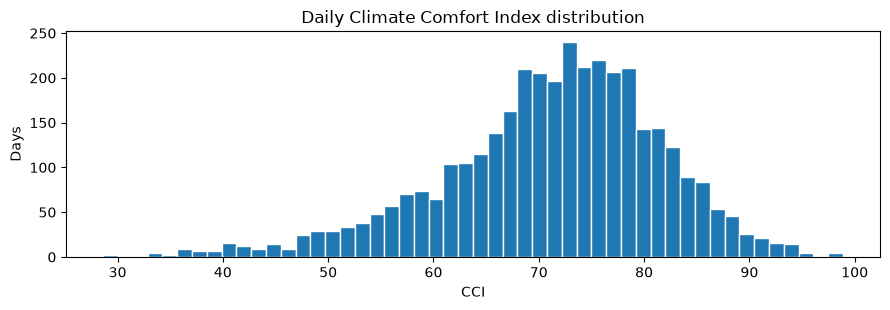

In [3]:
def calculate_cci(frame: pd.DataFrame) -> pd.DataFrame:
    """Add CCI component scores and the 0-100 daily Climate Comfort Index.

    Parameters
    ----------
    frame
        Daily-aggregated frame containing the five CCI input variables.

    Returns
    -------
    pd.DataFrame
        Copy of ``frame`` with five ``*_score`` columns and a ``cci`` column appended.
    """
    result = frame.copy()
    result["temp_score"] = (1 - (result["temperature_2m"] - 22).abs() / 20).clip(lower=0)
    result["humidity_score"] = (1 - (result["relative_humidity_2m"] - 50).abs() / 50).clip(lower=0)
    result["wind_score"] = (1 - (result["wind_speed_10m"] - 10).abs() / 40).clip(lower=0)
    result["cloud_score"] = (1 - result["cloud_cover"] / 100).clip(lower=0)
    result["rain_score"] = (1 - result["precipitation"] / 20).clip(lower=0)
    result["cci"] = 100 * (
        0.35 * result["temp_score"]
        + 0.20 * result["humidity_score"]
        + 0.15 * result["wind_score"]
        + 0.15 * result["cloud_score"]
        + 0.15 * result["rain_score"]
    )
    return result


CCI_SCORE_COLUMNS = ["temp_score", "humidity_score", "wind_score", "cloud_score", "rain_score"]
daily = calculate_cci(daily)

if not daily["cci"].dropna().between(0, 100).all():
    raise ValueError("CCI fell outside the documented 0-100 range.")

print("Component saturation (share of observed days scoring exactly 0):")
print((daily[CCI_SCORE_COLUMNS].dropna() == 0).mean().sort_values(ascending=False)
      .to_string(float_format="{:.1%}".format))

CCI_BANDS = pd.IntervalIndex.from_breaks([0, 20, 40, 60, 80, 100.01], closed="left")
CCI_BAND_LABELS = ["Very poor (0-19)", "Poor (20-39)", "Moderate (40-59)",
                   "Comfortable (60-79)", "Excellent (80-100)"]
band_counts = (
    pd.cut(daily["cci"], bins=CCI_BANDS).cat.rename_categories(CCI_BAND_LABELS)
    .value_counts().reindex(CCI_BAND_LABELS)
)
print("\nInterpretation bands:")
print(pd.DataFrame({"days": band_counts, "share": band_counts / band_counts.sum()})
      .to_string(formatters={"share": "{:.1%}".format}))

ax = daily["cci"].plot.hist(bins=50, figsize=(9, 3.2), color="tab:blue", edgecolor="white")
ax.set(title="Daily Climate Comfort Index distribution", xlabel="CCI", ylabel="Days")
ax.figure.tight_layout()

### 2.2 Weather Hazard Category (classification target)

Hazard scores, the continuous Weather Hazard Index and the four ordinal classes are
transcribed from the brief. Each hazard is bounded to `[0, 1]` by a minimum against 1.

| Hazard | Formula |
| --- | --- |
| `rain_hazard` | `min(precipitation / 30, 1)` |
| `wind_hazard` | `min(wind_gusts_10m / 100, 1)` |
| `cloud_hazard` | `min(cloud_cover / 100, 1)` |
| `snow_hazard` | `min(snowfall / 15, 1)` |
| `temp_hazard` | `min(abs(temperature_2m - 22) / 25, 1)` |

`WHI = 100 x (0.30 rain + 0.30 wind + 0.20 cloud + 0.10 snow + 0.10 temp)`

| Condition | Category | Class |
| --- | --- | --- |
| `WHI < 25` | Low Risk | 0 |
| `25 <= WHI < 50` | Moderate Risk | 1 |
| `50 <= WHI < 75` | High Risk | 2 |
| `WHI >= 75` | Extreme Risk | 3 |

**The model is trained on the class label, not on WHI.** The continuous index is retained as
`whi` for two legitimate purposes: as a same-day feature (section 3.2), and as an auxiliary
column on the target rows so that misclassifications can be examined against their distance
from a class boundary (section 4). It is never used as a predictor of its own future value.

**What to expect at this location.** Three of the five hazards are structurally small in Sydney.
Snowfall is zero, so `snow_hazard` contributes nothing; the 100 km/h gust denominator is far
above a typical Sydney gust; and the 25°C temperature denominator is generous for a temperate
coastal climate. Cloud cover is therefore the one hazard that is routinely substantial, which
pushes the bulk of the distribution around the 25-point Low/Moderate boundary and makes the
upper classes rare. The class distribution below is the single most consequential diagnostic in
this notebook: it determines whether accuracy is a meaningful metric, whether class weighting is
needed, and whether the 4-class problem is realistically a 2- or 3-class one. It is reported
here rather than discovered during model fitting.

Hazard saturation (share of observed days at the capped value of 1):
rain_hazard    1.40%
cloud_hazard   1.31%
wind_hazard    0.03%
snow_hazard    0.00%
temp_hazard    0.00%

Mean contribution to WHI, by hazard (weight x mean score x 100):
              points_of_whi share_of_mean_whi
wind_hazard           12.82             47.2%
cloud_hazard           9.79             36.0%
rain_hazard            2.53              9.3%
temp_hazard            2.02              7.4%
snow_hazard            0.00              0.0%

WHI summary: mean 27.1, sd 10.8, min 8.1, max 83.1

Weather Hazard Category distribution (full archive):
            category  days  share
class                            
0           Low Risk  1778 48.67%
1      Moderate Risk  1715 46.95%
2          High Risk   152  4.16%
3       Extreme Risk     8  0.22%


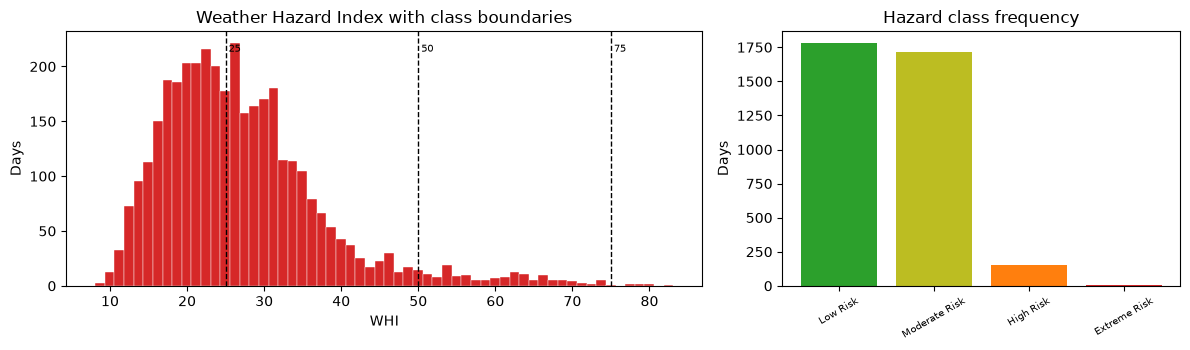

In [4]:
def calculate_whc(frame: pd.DataFrame) -> pd.DataFrame:
    """Add hazard scores, the Weather Hazard Index and the ordinal hazard class.

    Parameters
    ----------
    frame
        Daily-aggregated frame containing the five WHC input variables.

    Returns
    -------
    pd.DataFrame
        Copy of ``frame`` with five ``*_hazard`` columns, ``whi`` (0-100) and ``whc``
        (nullable integer class 0-3) appended.
    """
    result = frame.copy()
    result["rain_hazard"] = (result["precipitation"] / 30).clip(lower=0, upper=1)
    result["wind_hazard"] = (result["wind_gusts_10m"] / 100).clip(lower=0, upper=1)
    result["cloud_hazard"] = (result["cloud_cover"] / 100).clip(lower=0, upper=1)
    result["snow_hazard"] = (result["snowfall"] / 15).clip(lower=0, upper=1)
    result["temp_hazard"] = ((result["temperature_2m"] - 22).abs() / 25).clip(lower=0, upper=1)
    result["whi"] = 100 * (
        0.30 * result["rain_hazard"]
        + 0.30 * result["wind_hazard"]
        + 0.20 * result["cloud_hazard"]
        + 0.10 * result["snow_hazard"]
        + 0.10 * result["temp_hazard"]
    )
    # np.digitize maps NaN to the top bin, so the class is masked wherever WHI is missing.
    codes = np.digitize(result["whi"].to_numpy(dtype=float), bins=[25, 50, 75], right=False)
    result["whc"] = (
        pd.Series(codes, index=result.index, dtype="float64")
        .where(result["whi"].notna())
        .astype("Int64")
    )
    return result


WHC_HAZARD_COLUMNS = ["rain_hazard", "wind_hazard", "cloud_hazard", "snow_hazard", "temp_hazard"]
daily = calculate_whc(daily)

if not daily["whi"].dropna().between(0, 100).all():
    raise ValueError("WHI fell outside the documented 0-100 range.")

print("Hazard saturation (share of observed days at the capped value of 1):")
print((daily[WHC_HAZARD_COLUMNS].dropna() == 1).mean().sort_values(ascending=False)
      .to_string(float_format="{:.2%}".format))

print("\nMean contribution to WHI, by hazard (weight x mean score x 100):")
weights = {"rain_hazard": 0.30, "wind_hazard": 0.30, "cloud_hazard": 0.20,
           "snow_hazard": 0.10, "temp_hazard": 0.10}
contribution = pd.Series(
    {c: 100 * w * daily[c].mean() for c, w in weights.items()}
).sort_values(ascending=False)
print(pd.DataFrame({"points_of_whi": contribution,
                    "share_of_mean_whi": contribution / contribution.sum()})
      .to_string(formatters={"share_of_mean_whi": "{:.1%}".format}))

class_counts = daily["whc"].value_counts().reindex(list(WHC_LABELS)).fillna(0).astype(int)
class_table = pd.DataFrame({
    "category": [WHC_LABELS[c] for c in class_counts.index],
    "days": class_counts.to_numpy(),
    "share": class_counts.to_numpy() / class_counts.sum(),
}, index=pd.Index(class_counts.index, name="class"))
print(f"\nWHI summary: mean {daily['whi'].mean():.1f}, "
      f"sd {daily['whi'].std():.1f}, "
      f"min {daily['whi'].min():.1f}, max {daily['whi'].max():.1f}")
print("\nWeather Hazard Category distribution (full archive):")
print(class_table.to_string(formatters={"share": "{:.2%}".format}))

absent = [c for c in WHC_LABELS if class_counts.get(c, 0) == 0]
rare = [c for c in WHC_LABELS if 0 < class_counts.get(c, 0) < 30]
if absent:
    print(f"\nWARNING: class(es) {[WHC_LABELS[c] for c in absent]} never occur in this archive. "
          "The task is effectively lower-cardinality; see section 5 for the consequences.")
if rare:
    print(f"WARNING: class(es) {[WHC_LABELS[c] for c in rare]} have fewer than 30 days. "
          "Per-class recall will be unstable and macro-averaged metrics will be noisy.")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1.6, 1]})
axes[0].hist(daily["whi"].dropna(), bins=60, color="tab:red", edgecolor="white", linewidth=0.3)
for boundary in (25, 50, 75):
    axes[0].axvline(boundary, color="black", lw=1.0, ls="--")
    axes[0].text(boundary, axes[0].get_ylim()[1] * 0.92, f" {boundary}", fontsize=7)
axes[0].set(title="Weather Hazard Index with class boundaries", xlabel="WHI", ylabel="Days")
axes[1].bar([WHC_LABELS[c] for c in class_counts.index], class_counts.to_numpy(),
            color=["tab:green", "tab:olive", "tab:orange", "tab:red"])
axes[1].set(title="Hazard class frequency", ylabel="Days")
axes[1].tick_params(axis="x", labelrotation=30, labelsize=7)
fig.tight_layout()

### 2.3 How related are the two targets?

Worth establishing before any modelling, because it determines whether the two tasks are
genuinely distinct problems or two views of one.

If the correlation between CCI and WHI were close to -1, the hazard classifier would be little
more than a discretised comfort model and the second deliverable would add nothing. If the
relationship is strong but loose, the shared feature matrix is justified while the separate
models are still warranted, and the residual spread identifies the days where the two indices
disagree: gusty-but-clear days that are hazardous yet pleasant, and still, warm, overcast days
that are uncomfortable yet benign.

CCI vs WHI: Pearson r = -0.723, Spearman rho = -0.621

CCI distribution within each hazard class:
     count  mean  std   min   max
whc                              
0     1778 76.70 7.61 54.41 98.89
1     1715 67.64 8.48 36.40 93.31
2      152 47.62 7.01 33.09 66.37
3        8 38.12 6.66 28.63 47.24

Daily frame with both indices -> data/interim/sydney_daily.csv


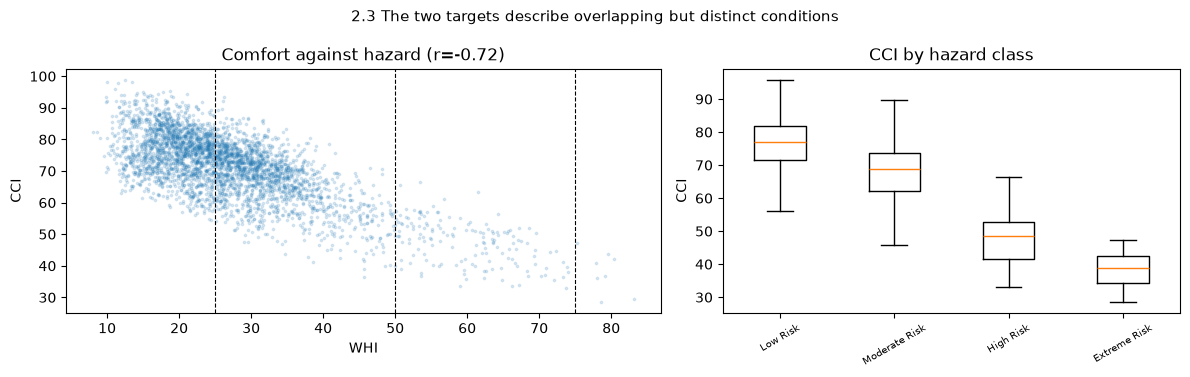

In [5]:
observed = daily.dropna(subset=["cci", "whi"])
pearson = observed["cci"].corr(observed["whi"])
spearman = observed["cci"].corr(observed["whi"], method="spearman")
print(f"CCI vs WHI: Pearson r = {pearson:.3f}, Spearman rho = {spearman:.3f}")

print("\nCCI distribution within each hazard class:")
print(observed.groupby("whc", observed=True)["cci"]
      .agg(["count", "mean", "std", "min", "max"]).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.3, 1]})
axes[0].scatter(observed["whi"], observed["cci"], s=3, alpha=0.15, color="tab:blue")
for boundary in (25, 50, 75):
    axes[0].axvline(boundary, color="black", lw=0.8, ls="--")
axes[0].set(title=f"Comfort against hazard (r={pearson:.2f})", xlabel="WHI", ylabel="CCI")

present = [c for c in WHC_LABELS if (observed["whc"] == c).any()]
axes[1].boxplot([observed.loc[observed["whc"] == c, "cci"] for c in present],
                tick_labels=[WHC_LABELS[c] for c in present], showfliers=False)
axes[1].set(title="CCI by hazard class", ylabel="CCI")
axes[1].tick_params(axis="x", labelrotation=30, labelsize=7)
fig.suptitle("2.3 The two targets describe overlapping but distinct conditions", fontsize=11)
fig.tight_layout()

INTERIM_PATH.parent.mkdir(parents=True, exist_ok=True)
daily.to_csv(INTERIM_PATH, index_label="date")
print(f"\nDaily frame with both indices -> {INTERIM_PATH.relative_to(PROJECT_ROOT)}")

## 3. Feature engineering (shared)

One feature matrix serves both tasks. Every column is computed from observations dated on or
before its own index date, which makes it valid for any forecast horizon — the comfort model's
+3 days and the hazard model's +7 days draw on exactly the same information set.

A single index value on day *t* is a weak feature set on its own: it collapses five variables
into one number, so a hot dry day and a mild overcast day scoring the same value become
indistinguishable despite having very different likely futures. The feature set therefore keeps
the raw daily variables and their recent history alongside both indices.

Each family below is built by its own function and documented in its own section, so the purpose
of every column is stated before it is created. `build_features` in section 3.9 composes them.

**The leakage rule applied throughout:** every column is produced by `shift(k)` with `k >= 0`,
or by a rolling window that is left-closed and ends at *t*. `center=True` is never used, as it
would look forward. Section 6 verifies this empirically by rebuilding features from a truncated
series.

| Section | Family | Columns |
| --- | --- | --- |
| 3.1 | Same-day observations | one per daily variable |
| 3.2 | Same-day component scores and indices | CCI scores + `cci`, hazard scores + `whi` |
| 3.3 | Lagged observations | base variables x 4 lags |
| 3.4 | Rolling means and standard deviations | 5 variables x 4 windows x 2 statistics |
| 3.5 | Rolling precipitation totals | 4 |
| 3.6 | Rolling gust maxima | 4 |
| 3.7 | Short-term deltas | base variables x 2 steps |
| 3.8 | Seasonal position | 2 |

### 3.0 Excluding variables that never vary

A column with no variance cannot inform a split, but it still consumes a slot in the feature
vector, appears in importance tables with a misleading zero, and must be constructed by the API
at request time. Such columns are identified once and excluded.

Two details matter for correctness:

- **The decision is made on the training period only** (`< 2024-01-01`). Deciding on the full
  archive would let the test period influence which columns exist, which is feature selection on
  test data even though the effect here is negligible.
- **The list is fixed globally**, not recomputed per call. The leakage test in section 6 rebuilds
  features from a truncated series and compares values; if the exclusion set were recomputed
  from whatever slice was passed in, the two runs could produce different columns and the
  comparison would be meaningless.

For a Sydney sea-level extract this removes `snowfall` and its derived `snow_hazard`. That is a
substantive finding rather than housekeeping: it means one of the five WHC hazard terms is
structurally inert at this location, and the effective hazard formula has four contributors, not
five.

In [6]:
DAILY_VARIABLES = list(dict.fromkeys([*CCI_COLUMNS, *WHC_COLUMNS, *sorted(available_optional)]))
INDEX_COLUMNS = [*CCI_SCORE_COLUMNS, "cci", *WHC_HAZARD_COLUMNS, "whi"]

# Decided on the training period only, and fixed for the rest of the notebook.
_training_slice = daily.loc[daily.index < VAL_START]
ZERO_VARIANCE_COLUMNS = [
    column for column in [*DAILY_VARIABLES, *INDEX_COLUMNS]
    if _training_slice[column].nunique(dropna=True) <= 1
]

MODEL_VARIABLES = [c for c in DAILY_VARIABLES if c not in ZERO_VARIANCE_COLUMNS]
MODEL_INDEX_COLUMNS = [c for c in INDEX_COLUMNS if c not in ZERO_VARIANCE_COLUMNS]

print(f"Excluded {len(ZERO_VARIANCE_COLUMNS)} constant column(s): "
      f"{ZERO_VARIANCE_COLUMNS or 'none'}")
print(f"Feature base variables ({len(MODEL_VARIABLES)}): {MODEL_VARIABLES}")
print(f"Feature index columns ({len(MODEL_INDEX_COLUMNS)}): {MODEL_INDEX_COLUMNS}")

Excluded 2 constant column(s): ['snowfall', 'snow_hazard']
Feature base variables (6): ['temperature_2m', 'relative_humidity_2m', 'wind_speed_10m', 'cloud_cover', 'precipitation', 'wind_gusts_10m']
Feature index columns (11): ['temp_score', 'humidity_score', 'wind_score', 'cloud_score', 'rain_score', 'cci', 'rain_hazard', 'wind_hazard', 'cloud_hazard', 'temp_hazard', 'whi']


### Plot helpers

Each family below is inspected visually as well as described. Two standard views are used:

- a **distribution grid**, one histogram per column, which exposes skew, zero-inflation,
  saturation against a bound, and implausible values that a mean and standard deviation would
  conceal;
- a **series grid**, one time series per column over the most recent two years, which shows
  whether a feature actually varies at the daily timescale the model operates on, and whether it
  carries the seasonal cycle.

Figures are written under `reports/figures/` so they can be referenced directly from the report
rather than re-generated: shared feature diagnostics to `preprocessing/`, and target-specific
diagnostics to `comfort_climate/` and `weather_hazard/`.

In [7]:
def save_figure(fig, name: str, subdir: str = "preprocessing") -> None:
    """Write a figure to a report figures subdirectory under a stable name."""
    directory = FIGURE_ROOT / subdir
    directory.mkdir(parents=True, exist_ok=True)
    fig.savefig(directory / f"{name}.png", dpi=150, bbox_inches="tight")


def _panel_grid(n: int, ncols: int, panel_height: float = 1.85):
    """Return a figure and a flat array of axes sized for ``n`` panels."""
    ncols = max(1, min(ncols, n))
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.0 * ncols, panel_height * nrows))
    axes = np.atleast_1d(axes).ravel()
    for axis in axes[n:]:
        axis.axis("off")
    return fig, axes[:n]


def distribution_grid(frame: pd.DataFrame, title: str, name: str, ncols: int = 4,
                      subdir: str = "preprocessing"):
    """Plot a histogram for every column, one panel each.

    Distributions reveal skew, zero-inflation, saturation at a bound, and implausible values
    that summary statistics alone would hide.
    """
    columns = list(frame.columns)
    fig, axes = _panel_grid(len(columns), ncols)
    for axis, column in zip(axes, columns):
        axis.hist(frame[column].dropna(), bins=40, color="tab:blue", edgecolor="white",
                  linewidth=0.3)
        axis.set_title(column, fontsize=7)
        axis.tick_params(labelsize=6)
        axis.set_ylabel("")
    fig.suptitle(title, fontsize=11)
    fig.tight_layout()
    save_figure(fig, name, subdir)
    return fig


def series_grid(frame: pd.DataFrame, title: str, name: str, ncols: int = 4, years: int = 2,
                subdir: str = "preprocessing"):
    """Plot the most recent ``years`` of every column as a time series, one panel each.

    A window is used rather than the full history so that day-to-day behaviour stays legible.
    """
    window = frame.loc[frame.index > frame.index.max() - pd.DateOffset(years=years)]
    columns = list(window.columns)
    fig, axes = _panel_grid(len(columns), ncols)
    for axis, column in zip(axes, columns):
        axis.plot(window.index, window[column], color="tab:blue", lw=0.6)
        axis.set_title(column, fontsize=7)
        axis.tick_params(labelsize=5)
        for label in axis.get_xticklabels():
            label.set_rotation(30)
    fig.suptitle(f"{title} (last {years} years)", fontsize=11)
    fig.tight_layout()
    save_figure(fig, name, subdir)
    return fig


print(f"Plot helpers ready. Figures are written under "
      f"{FIGURE_ROOT.relative_to(PROJECT_ROOT)}/ for use in the report.")

Plot helpers ready. Figures are written under reports/figures/ for use in the report.


### 3.1 Same-day observations

The daily aggregates for day *t* itself. These are the strongest predictors at short horizons,
because tomorrow's weather resembles today's more than it resembles anything else available.

| Column | What it is | Why it is included |
| --- | --- | --- |
| `temperature_2m` | Mean 2 m air temperature on *t*, °C | The dominant CCI component (weight 0.35) and a WHC hazard term. Strongly autocorrelated day to day, so today's value anchors the next several. |
| `relative_humidity_2m` | Mean relative humidity on *t*, % | Second-heaviest CCI component (0.20). Also a proxy for air-mass type: humid air masses persist and suppress the diurnal temperature range. |
| `wind_speed_10m` | Mean 10 m wind speed on *t*, km/h | CCI component (0.15). Elevated wind often accompanies a synoptic system that will still be present tomorrow. |
| `cloud_cover` | Mean total cloud cover on *t*, % | Component of both indices (CCI 0.15, WHI 0.20). Persistent overcast indicates an established system rather than a passing shower. |
| `precipitation` | Total precipitation on *t*, mm | Component of both indices (CCI 0.15, WHI 0.30). Rain days cluster, so a wet day raises the odds the next is wet too. |
| `wind_gusts_10m` | Maximum gust on *t*, km/h | The heaviest WHI term jointly with rain (0.30). Also distinguishes a steadily breezy day from a convectively unstable one, and instability today often means showers in the following days. |

`snowfall` is listed in the WHC brief but is excluded here by the rule in section 3.0. The
following are included only when present in the raw extract; none appears in either formula,
and each is included because it carries information about *where the weather is going* that the
formula inputs do not.

| Column | What it is | Why it is included |
| --- | --- | --- |
| `pressure_msl` | Mean sea-level pressure on *t*, hPa | The single most useful non-formula predictor. Low and falling pressure signals an approaching frontal system, which is precisely the multi-day change both models are asked to anticipate. |
| `dew_point_2m` | Mean dew point on *t*, °C | An absolute measure of moisture, unlike relative humidity which moves with temperature. Air-mass changes show up here more cleanly. |
| `apparent_temperature` | Mean feels-like temperature on *t*, °C | Combines temperature, humidity, wind and radiation. A compact summary; expected to correlate with `temp_score` and may prove redundant. |
| `shortwave_radiation` | Mean incoming shortwave radiation on *t*, W/m² | An independent measure of effective cloudiness, less noisy than the cloud-cover percentage. |

In [8]:
def same_day_observations(frame: pd.DataFrame) -> pd.DataFrame:
    """Return the daily observations for day *t* itself.

    Parameters
    ----------
    frame
        Daily frame indexed by date.

    Returns
    -------
    pd.DataFrame
        One column per ingested, non-constant daily variable, unshifted.
    """
    return frame[MODEL_VARIABLES].copy()


preview = same_day_observations(daily)
print(f"3.1 same-day observations: {preview.shape[1]} columns")
print(list(preview.columns))
preview.tail(3)

3.1 same-day observations: 6 columns
['temperature_2m', 'relative_humidity_2m', 'wind_speed_10m', 'cloud_cover', 'precipitation', 'wind_gusts_10m']


,temperature_2m,relative_humidity_2m,wind_speed_10m,cloud_cover,precipitation,wind_gusts_10m
time,,,,,,
2025-12-29,18.32,61.38,8.90,20.29,0.00,40.70
2025-12-30,18.80,64.29,8.35,41.67,0.00,40.00
2025-12-31,19.47,73.04,8.35,91.79,0.40,38.90


#### Visual check

Both views matter for this family. The distributions confirm the physical plausibility of each
variable and expose the shape of precipitation, which is heavily zero-inflated: most days record
no rain at all, and the mean is driven by a small number of large days. Gusts should look
roughly bell-shaped with a long right tail, and the position of that tail relative to the
100 km/h WHI denominator explains why `wind_hazard` rarely saturates.

The series show which variables carry a visible annual cycle — temperature strongly, cloud cover
and wind much less — which is the first evidence for including the seasonal encoding in
section 3.8.

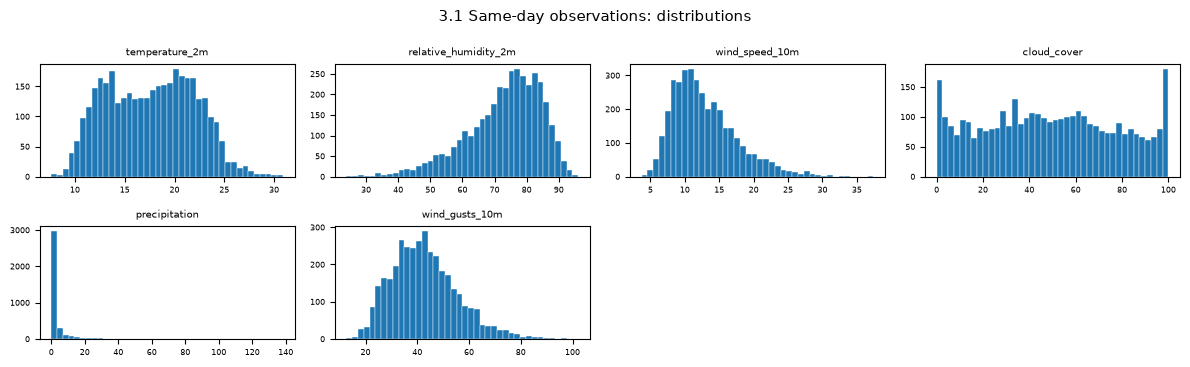

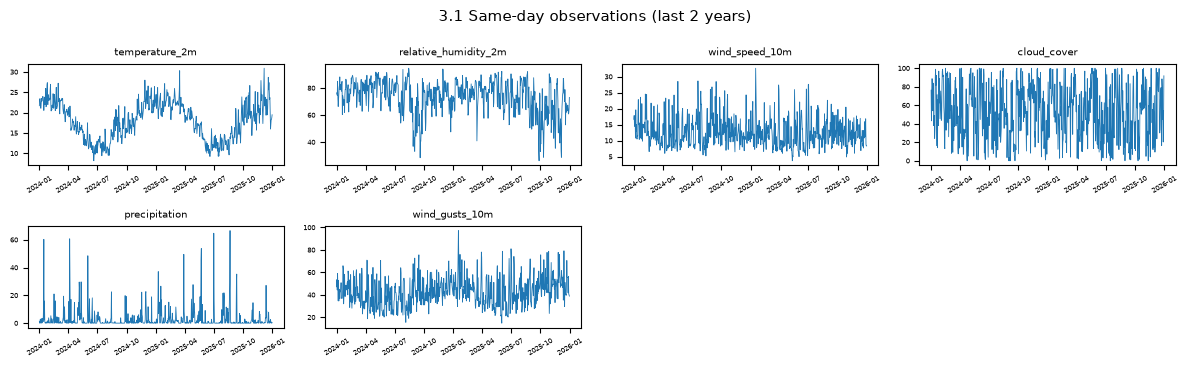

In [9]:
same_day_obs = same_day_observations(daily)
distribution_grid(same_day_obs, "3.1 Same-day observations: distributions",
                  "features-31-same-day-observations-dist")
series_grid(same_day_obs, "3.1 Same-day observations",
            "features-31-same-day-observations-series")
plt.show()

### 3.2 Same-day component scores and indices

The bounded component scores and both composite indices for day *t*.

The raw variables in 3.1 and the scores here are not redundant with each other. A score encodes
*distance from a reference*, which the raw value does not: 12°C and 32°C are far apart as
temperatures but score identically at 0.5 on `temp_score`. Supplying both lets a tree split on
either the physical value or the transformed penalty, whichever separates the target better.

**Comfort components**

| Column | What it is | Why it is included |
| --- | --- | --- |
| `temp_score` | `max(0, 1 - abs(T - 22) / 20)` on *t* | Distance from the 22°C comfort optimum. Isolates the largest single driver of CCI. |
| `humidity_score` | `max(0, 1 - abs(RH - 50) / 50)` on *t* | Symmetric, so it treats dry and muggy days as equally uncomfortable — information the raw percentage does not carry. |
| `wind_score` | `max(0, 1 - abs(W - 10) / 40)` on *t* | Distance from a 10 km/h light breeze. Penalises both still and gusty days. |
| `cloud_score` | `max(0, 1 - cloud / 100)` on *t* | Linear clear-sky preference; a monotone rescaling retained so all five components sit on one scale. |
| `rain_score` | `max(0, 1 - precip / 20)` on *t* | Dryness score, saturating at zero for any day of 20 mm or more. |
| `cci` | Weighted sum, 0–100 | The persistence feature and the basis of the comfort baseline. Same quantity as the regression target but observed on *t*, so it is known at prediction time. |

**Hazard components**

| Column | What it is | Why it is included |
| --- | --- | --- |
| `rain_hazard` | `min(precip / 30, 1)` on *t* | Rain on the hazard scale, which saturates 50% later than `rain_score` does. The pair together locates a wet day on both scales at once. |
| `wind_hazard` | `min(gust / 100, 1)` on *t* | Gusts as a share of a destructive gust. |
| `cloud_hazard` | `min(cloud / 100, 1)` on *t* | Cloud on the hazard scale — the monotone inverse of `cloud_score`, retained for interpretability of hazard importances. |
| `temp_hazard` | `min(abs(T - 22) / 25, 1)` on *t* | Thermal extremity, a wider tolerance than `temp_score` uses. |
| `whi` | Weighted sum, 0–100 | The persistence feature and the basis of the hazard baseline: the class label at *t* follows directly from it. |

`snow_hazard` is excluded by the rule in section 3.0. Several of these columns are strongly
correlated with their comfort counterparts by construction, which the matrix overview in 3.9
makes visible. They are kept because correlated predictors cost a tree ensemble little, whereas
omitting the hazard scale would force the classifier to relearn each threshold from the raw
variable.

In [10]:
def same_day_indices(frame: pd.DataFrame) -> pd.DataFrame:
    """Return the CCI and WHI component scores and both composite indices for day *t*."""
    return frame[MODEL_INDEX_COLUMNS].copy()


preview = same_day_indices(daily)
print(f"3.2 same-day scores and indices: {preview.shape[1]} columns")
print(list(preview.columns))
preview.tail(3)

3.2 same-day scores and indices: 11 columns
['temp_score', 'humidity_score', 'wind_score', 'cloud_score', 'rain_score', 'cci', 'rain_hazard', 'wind_hazard', 'cloud_hazard', 'temp_hazard', 'whi']


,temp_score,humidity_score,wind_score,cloud_score,rain_score,cci,rain_hazard,wind_hazard,cloud_hazard,temp_hazard,whi
time,,,,,,,,,,,
2025-12-29,0.82,0.77,0.97,0.80,1.00,85.55,0.00,0.41,0.20,0.15,17.74
2025-12-30,0.84,0.71,0.96,0.58,1.00,81.81,0.00,0.40,0.42,0.13,21.61
2025-12-31,0.87,0.54,0.96,0.08,0.98,71.66,0.01,0.39,0.92,0.10,31.44


#### Visual check

The score distributions should look markedly different from the raw variables they derive from.
Look for the spike at zero in `rain_score` (every day of 20 mm or more collapses to the same
value), the compression of `temp_score` toward the upper end, which reflects Sydney sitting close
to the 22°C optimum for much of the year, and the mirror-image shapes of `cloud_score` and
`cloud_hazard`.

A component whose distribution is nearly constant contributes little discriminating power,
which is worth knowing before model fitting rather than after. The `whi` panel is the most
important one to read: it shows how much of the distribution sits near the 25-point class
boundary, and therefore how many days the classifier will have to separate on fine margins.

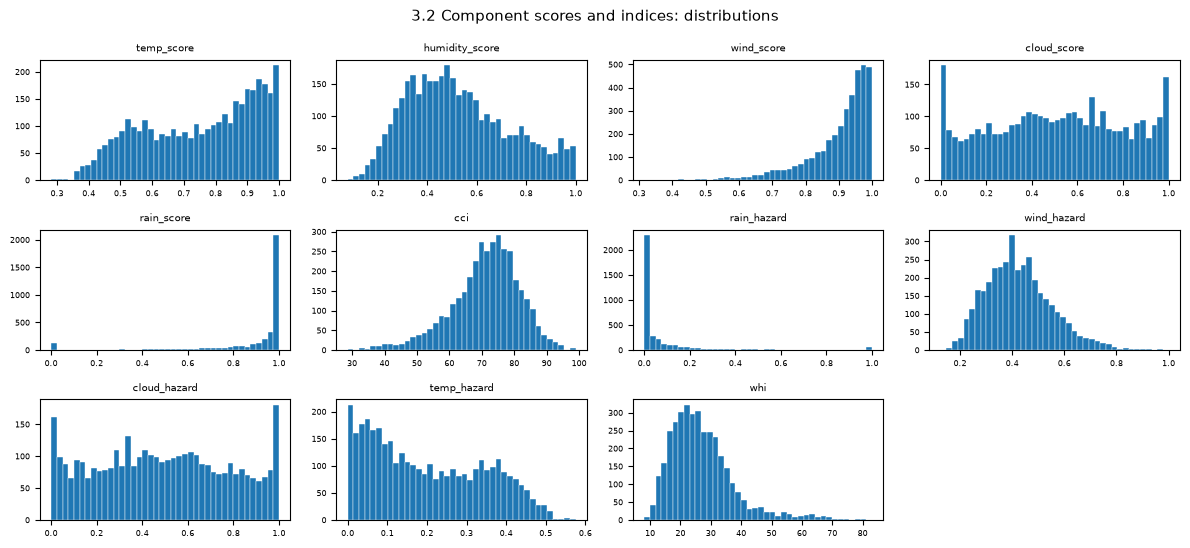

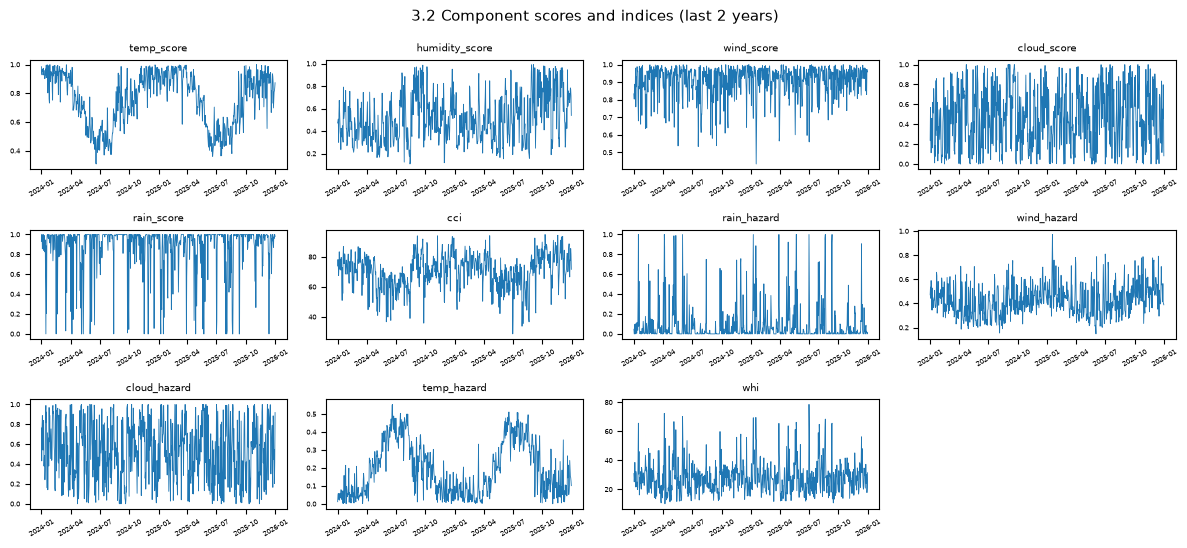

In [11]:
same_day_index_frame = same_day_indices(daily)
distribution_grid(same_day_index_frame, "3.2 Component scores and indices: distributions",
                  "features-32-indices-dist", ncols=4)
series_grid(same_day_index_frame, "3.2 Component scores and indices",
            "features-32-indices-series", ncols=4)
plt.show()

### 3.3 Lagged observations

Values from *t*−1, *t*−2, *t*−3 and *t*−7, produced with `shift(k)` for positive `k`.

A single day is a snapshot. Lags give the model a short trajectory, so it can distinguish a warm
day at the end of a cooling trend from a warm day at the start of a heatwave — two states with
the same `temperature_2m` and very different futures.

**What each lag distance contributes**

| Lag | Column suffix | Purpose |
| --- | --- | --- |
| 1 day | `_lag1` | Yesterday. Combined with the same-day value it gives the immediate direction of travel. |
| 2 days | `_lag2` | Extends the trajectory enough to distinguish a steady trend from a one-day fluctuation. |
| 3 days | `_lag3` | Roughly the residence time of a synoptic system over Sydney, so it captures the current system as a whole. |
| 7 days | `_lag7` | The same weekday one week earlier. A short-term local climatology reference, largely free of the seasonal drift a 30-day lag would carry. For the hazard task it is also the value observed exactly one horizon ago, which is the natural reference point for a +7 day forecast. |

**Which variables are lagged**

| Base variable | Columns generated | What the history adds |
| --- | --- | --- |
| `temperature_2m` | `temperature_2m_lag{1,2,3,7}` | Warming or cooling trend, and its steepness. |
| `relative_humidity_2m` | `..._lag{1,2,3,7}` | Moistening or drying, which typically precedes a change in cloud and rain. |
| `wind_speed_10m` | `..._lag{1,2,3,7}` | Whether wind is building or easing — building wind often precedes a front. |
| `cloud_cover` | `..._lag{1,2,3,7}` | Whether cloud is thickening or clearing. |
| `precipitation` | `..._lag{1,2,3,7}` | Recent rain history, which clusters strongly. |
| `wind_gusts_10m` | `..._lag{1,2,3,7}` | Recent storminess, the heaviest hazard driver after rain. |
| `cci`, `whi` | `cci_lag{...}`, `whi_lag{...}` | The trajectory of each target index itself; the most direct trend signal available. |
| optional variables | `pressure_msl_lag{...}`, etc. | Pressure lags are the most valuable here: the *change* in pressure over several days is the classic frontal indicator, and section 3.7 derives it from these. |

In [12]:
# Lag every ingested daily variable plus both indices.
LAG_BASE = [*MODEL_VARIABLES, *[c for c in ("cci", "whi") if c in MODEL_INDEX_COLUMNS]]


def lagged_observations(frame: pd.DataFrame) -> pd.DataFrame:
    """Return values from *t*-1, *t*-2, *t*-3 and *t*-7 for each base variable.

    Uses positive shifts only, so every column depends solely on the past.
    """
    return pd.DataFrame(
        {f"{column}_lag{lag}": frame[column].shift(lag)
         for column in LAG_BASE for lag in LAG_DAYS},
        index=frame.index,
    )


preview = lagged_observations(daily)
print(f"3.3 lagged observations: {preview.shape[1]} columns "
      f"({len(LAG_BASE)} variables x {len(LAG_DAYS)} lags)")
preview.tail(3).iloc[:, :4]

3.3 lagged observations: 32 columns (8 variables x 4 lags)


,temperature_2m_lag1,temperature_2m_lag2,temperature_2m_lag3,temperature_2m_lag7
time,,,,
2025-12-29,18.22,17.06,15.96,25.49
2025-12-30,18.32,18.22,17.06,23.29
2025-12-31,18.80,18.32,18.22,23.69


#### Visual check

A lagged column has the same marginal distribution as its source, so histograms of all of them
add little. The informative view is how the relationship with the present decays as the lag
grows.

The first figure plots the correlation between each base variable at *t* and the same variable
at each lag. A slow decay means the variable is highly persistent, so its lags are largely
redundant with the same-day value; a steep decay means each lag carries new information. This is
the evidence for keeping or dropping lag depth, and should be read alongside the ablation
results in the modelling notebooks.

The second figure overlays each index with its own lags over a short window, making the shift
visible directly and confirming the lags move backwards in time, never forwards.

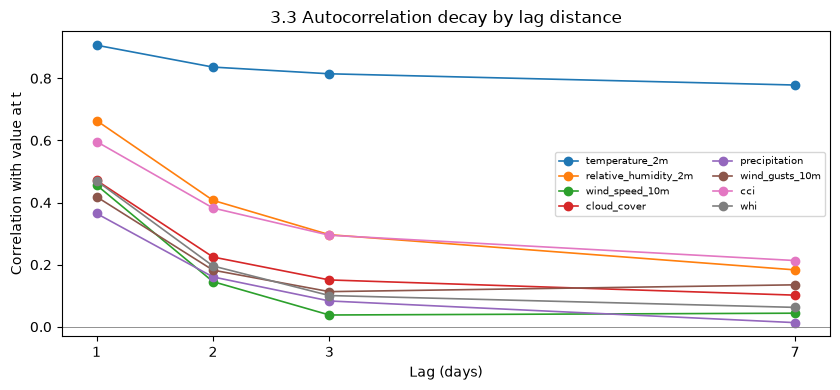

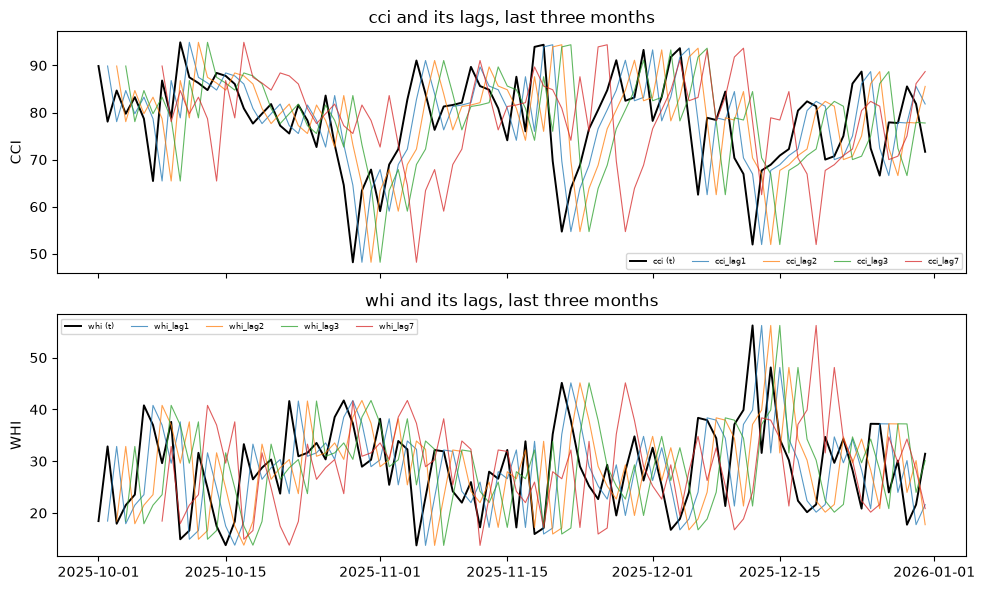

In [13]:
lag_frame = lagged_observations(daily)

fig, axis = plt.subplots(figsize=(8.5, 4))
for column in LAG_BASE:
    correlations = [daily[column].corr(daily[column].shift(lag)) for lag in LAG_DAYS]
    axis.plot(LAG_DAYS, correlations, marker="o", lw=1.2, label=column)
axis.set(title="3.3 Autocorrelation decay by lag distance", xlabel="Lag (days)",
         ylabel="Correlation with value at t", xticks=list(LAG_DAYS))
axis.axhline(0, color="grey", lw=0.6)
axis.legend(fontsize=7, ncol=2)
fig.tight_layout()
save_figure(fig, "features-33-lag-autocorrelation")

recent = daily.loc[daily.index > daily.index.max() - pd.DateOffset(months=3)]
index_columns = [c for c in ("cci", "whi") if c in MODEL_INDEX_COLUMNS]
fig, axes = plt.subplots(len(index_columns), 1, figsize=(10, 3.0 * len(index_columns)),
                         sharex=True)
for axis, column in zip(np.atleast_1d(axes), index_columns):
    axis.plot(recent.index, recent[column], color="black", lw=1.4, label=f"{column} (t)")
    for lag in LAG_DAYS:
        axis.plot(recent.index, recent[column].shift(lag), lw=0.8, alpha=0.75,
                  label=f"{column}_lag{lag}")
    axis.set(title=f"{column} and its lags, last three months", ylabel=column.upper())
    axis.legend(fontsize=6, ncol=5)
fig.tight_layout()
save_figure(fig, "features-33-index-lags-overlay")
plt.show()

### 3.4 Rolling means and standard deviations

Windows of 3, 7, 14 and 30 days ending on *t*, for five variables, giving a mean and a standard
deviation each.

Individual lags are noisy — one unusual day moves them a lot. A rolling mean is a smoothed
estimate of the current regime, and the standard deviation over the same window says how settled
that regime is. Volatility is separately useful: a stable high-pressure spell is far more
predictable a week out than an unsettled one, and a model can learn to lean harder on
persistence when the recent standard deviation is low.

Multiple window lengths are provided rather than one because they measure different things: 3
days is the current system, 30 days is the season-to-date baseline, and 7 and 14 sit between.
The longer windows matter more for the hazard task than for comfort, because at a 7-day horizon
the current system has usually cleared and the prevailing regime is most of what remains.

| Base variable | Columns generated | What the mean captures | What the standard deviation captures |
| --- | --- | --- | --- |
| `temperature_2m` | `temperature_2m_roll{3,7,14,30}_{mean,std}` | The prevailing thermal regime, and via the 30-day window an implicit local climatology the model can use as a fallback. | Temperature variability — high values indicate frontal passages rather than a settled air mass. |
| `relative_humidity_2m` | `..._roll{3,7,14,30}_{mean,std}` | Whether the period has been broadly humid or dry. | Swings in moisture, which accompany air-mass changes. |
| `cloud_cover` | `..._roll{3,7,14,30}_{mean,std}` | Sustained cloudiness versus intermittent cover. Cloud is the largest routine contributor to WHI, so its regime matters directly to the hazard class. | Whether cloud has been consistent or alternating. |
| `cci` | `cci_roll{3,7,14,30}_{mean,std}` | The recent comfort level, smoothed. The 30-day mean approximates a seasonal climatology estimate. | Comfort volatility, a direct measure of how hard the coming days are likely to be to predict. |
| `whi` | `whi_roll{3,7,14,30}_{mean,std}` | The recent hazard level. Because the class label is a threshold on WHI, a rolling mean sitting near 25 flags a period where the class can flip on small changes. | Hazard volatility, which separates a persistently marginal period from one swinging across boundaries. |

`min_periods` is set equal to the window, so a partial window yields `NaN` rather than a value
computed from fewer days. Those rows are removed by the warm-up filter in section 4 instead of
being silently filled.

In [14]:
# Variables smooth enough for a rolling mean to be meaningful. Precipitation and gusts are
# excluded here and handled in 3.5 and 3.6, where a sum and a maximum are the right statistics.
ROLL_STAT_BASE = [
    column for column in
    ["temperature_2m", "relative_humidity_2m", "cloud_cover", "cci", "whi"]
    if column in MODEL_VARIABLES or column in MODEL_INDEX_COLUMNS
]


def rolling_statistics(frame: pd.DataFrame) -> pd.DataFrame:
    """Return rolling means and standard deviations over windows ending on *t*.

    Windows are left-closed (``center`` is left at its default of ``False``) and require a full
    window, so no value depends on a future observation.
    """
    columns = {}
    for column in ROLL_STAT_BASE:
        for window in ROLLING_WINDOWS:
            rolled = frame[column].rolling(window, min_periods=window)
            columns[f"{column}_roll{window}_mean"] = rolled.mean()
            columns[f"{column}_roll{window}_std"] = rolled.std()
    return pd.DataFrame(columns, index=frame.index)


preview = rolling_statistics(daily)
print(f"3.4 rolling statistics: {preview.shape[1]} columns "
      f"({len(ROLL_STAT_BASE)} variables x {len(ROLLING_WINDOWS)} windows x 2 statistics)")
preview.tail(3).iloc[:, :4]

3.4 rolling statistics: 40 columns (5 variables x 4 windows x 2 statistics)


,temperature_2m_roll3_mean,temperature_2m_roll3_std,temperature_2m_roll7_mean,temperature_2m_roll7_std
time,,,,
2025-12-29,17.87,0.70,19.43,2.98
2025-12-30,18.45,0.31,18.79,2.45
2025-12-31,18.86,0.58,18.19,1.29


#### Visual check

Three views are used here because means and standard deviations do different jobs.

The first shows each rolling mean overlaid on the raw daily series: longer windows should trace
a progressively smoother path, with the 30-day mean approximating a seasonal baseline rather
than tracking individual weather systems. If a long window looks as jagged as the raw series,
the smoothing is not working as intended.

The second plots the rolling standard deviations, which measure how unsettled the recent period
has been. Peaks should coincide with visibly volatile stretches in the first figure.

The third gives the full distribution grid so that every rolling column is inspected, not only
the representative ones.

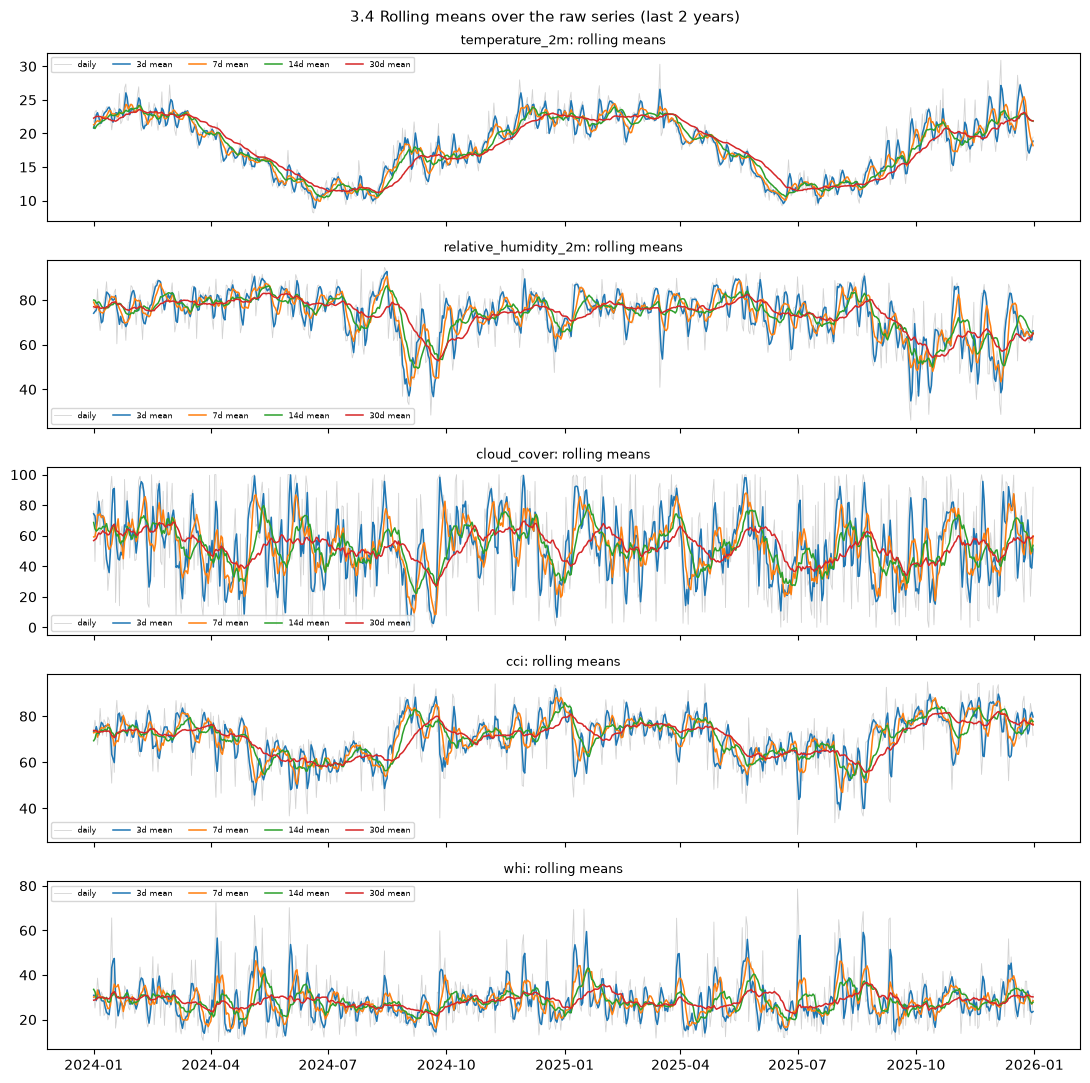

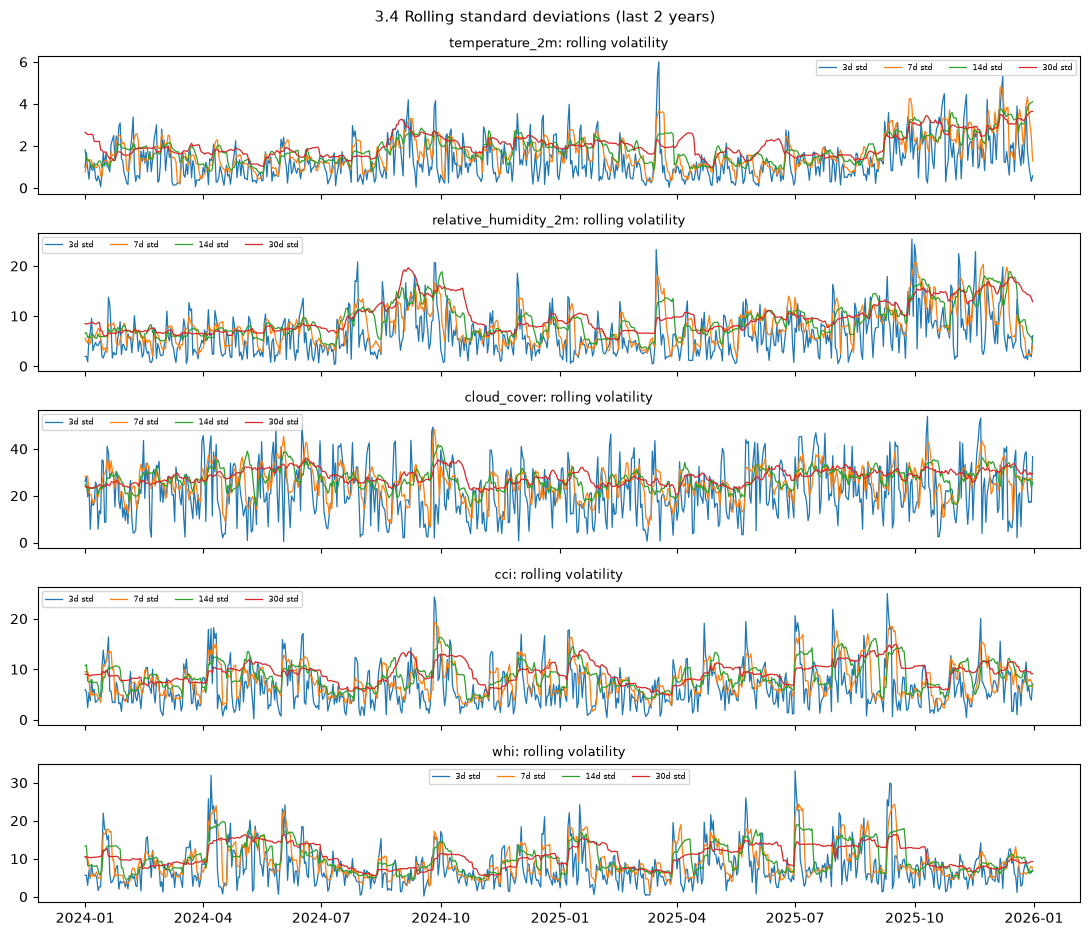

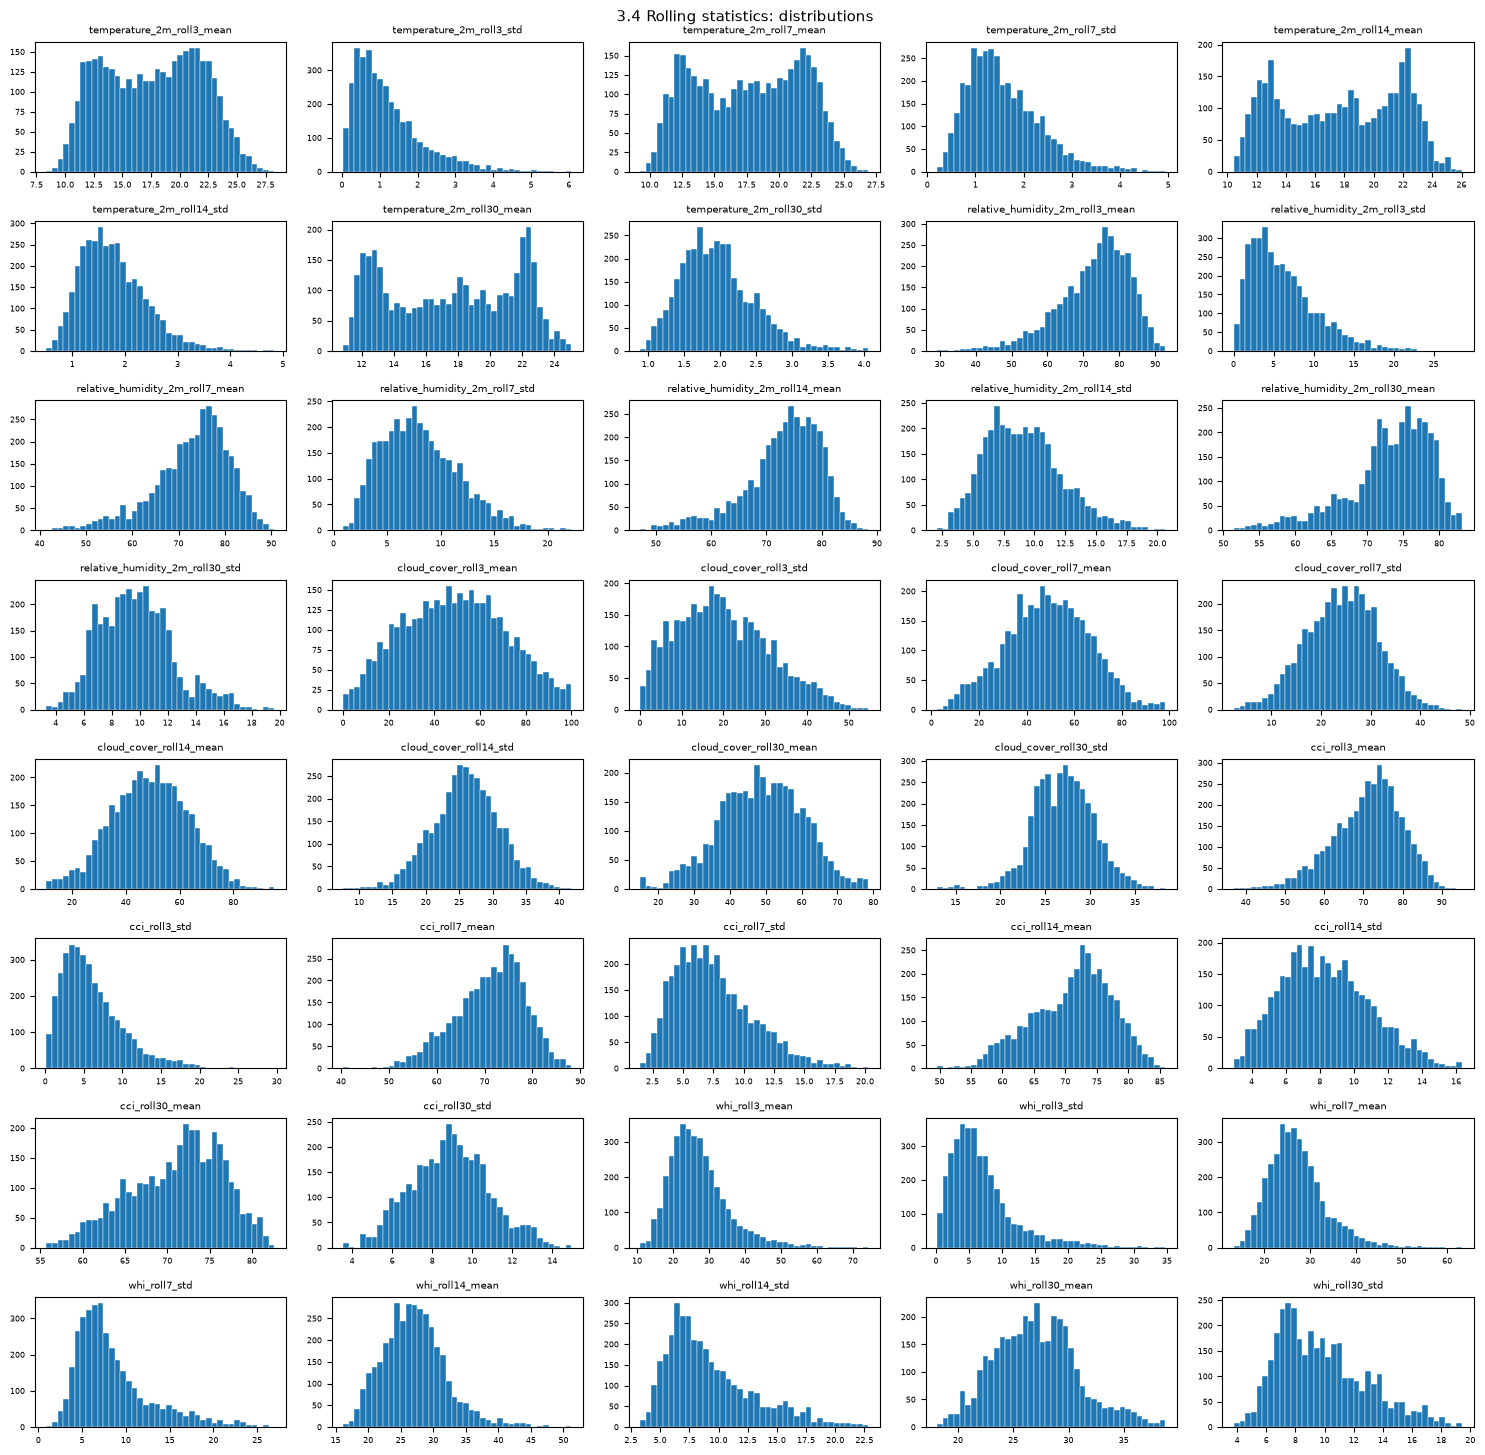

In [15]:
rolling_frame = rolling_statistics(daily)
window_years = 2
recent = daily.loc[daily.index > daily.index.max() - pd.DateOffset(years=window_years)]

fig, axes = plt.subplots(len(ROLL_STAT_BASE), 1, figsize=(11, 2.2 * len(ROLL_STAT_BASE)),
                         sharex=True)
for axis, column in zip(np.atleast_1d(axes), ROLL_STAT_BASE):
    axis.plot(recent.index, recent[column], color="lightgrey", lw=0.6, label="daily")
    for window in ROLLING_WINDOWS:
        smoothed = rolling_frame[f"{column}_roll{window}_mean"].reindex(recent.index)
        axis.plot(recent.index, smoothed, lw=1.1, label=f"{window}d mean")
    axis.set_title(f"{column}: rolling means", fontsize=9)
    axis.legend(fontsize=6, ncol=5)
fig.suptitle(f"3.4 Rolling means over the raw series (last {window_years} years)", fontsize=11)
fig.tight_layout()
save_figure(fig, "features-34-rolling-means-overlay")

fig, axes = plt.subplots(len(ROLL_STAT_BASE), 1, figsize=(11, 1.9 * len(ROLL_STAT_BASE)),
                         sharex=True)
for axis, column in zip(np.atleast_1d(axes), ROLL_STAT_BASE):
    for window in ROLLING_WINDOWS:
        volatility = rolling_frame[f"{column}_roll{window}_std"].reindex(recent.index)
        axis.plot(recent.index, volatility, lw=0.9, label=f"{window}d std")
    axis.set_title(f"{column}: rolling volatility", fontsize=9)
    axis.legend(fontsize=6, ncol=4)
fig.suptitle(f"3.4 Rolling standard deviations (last {window_years} years)", fontsize=11)
fig.tight_layout()
save_figure(fig, "features-34-rolling-std-series")

distribution_grid(rolling_frame, "3.4 Rolling statistics: distributions",
                  "features-34-rolling-dist", ncols=5)
plt.show()

### 3.5 Rolling precipitation totals

Precipitation is summed, not averaged. A mean daily rainfall over a window is hard to interpret
and loses the quantity that matters, which is how much water has actually fallen.

| Column | What it is | Why it is included |
| --- | --- | --- |
| `precipitation_roll3_sum` | Total rainfall over *t*−2 to *t*, mm | Identifies an active wet spell. Consecutive wet days indicate a stalled system likely to persist into the forecast window. |
| `precipitation_roll7_sum` | Total rainfall over the week ending *t*, mm | Weekly wetness, smoothing over individual dry days within an unsettled period. |
| `precipitation_roll14_sum` | Total rainfall over the fortnight ending *t*, mm | Medium-term wetness, useful for separating a genuinely wet month from an isolated storm. |
| `precipitation_roll30_sum` | Total rainfall over the month ending *t*, mm | Approximates the prevailing regime — drought versus a wet pattern — which shifts the base rate of rain in the coming days. |

Rainfall is the heaviest single WHI term (0.30, jointly with gusts) and a 0.15 CCI term, so
these columns serve both tasks. Rainfall is heavily zero-inflated and right-skewed, so the
totals are dominated by a small number of large days; that is expected and is why the
distributions are inspected rather than assumed to be well behaved.

In [16]:
def rolling_precipitation(frame: pd.DataFrame) -> pd.DataFrame:
    """Return accumulated rainfall over windows ending on *t*."""
    return pd.DataFrame(
        {f"precipitation_roll{window}_sum":
         frame["precipitation"].rolling(window, min_periods=window).sum()
         for window in ROLLING_WINDOWS},
        index=frame.index,
    )


preview = rolling_precipitation(daily)
print(f"3.5 rolling precipitation totals: {preview.shape[1]} columns")
preview.tail(3)

3.5 rolling precipitation totals: 4 columns


,precipitation_roll3_sum,precipitation_roll7_sum,precipitation_roll14_sum,precipitation_roll30_sum
time,,,,
2025-12-29,1.30,5.80,16.40,68.00
2025-12-30,0.80,5.80,16.00,67.50
2025-12-31,0.40,6.20,16.40,67.70


#### Visual check

Rainfall totals are strongly right-skewed, so the histograms are drawn on a logarithmic count
axis; on a linear axis the zero bar dominates and the tail that actually drives `rain_score` and
`rain_hazard` becomes invisible.

The series view shows accumulation behaviour: short windows spike and reset, while the 30-day
total moves slowly and acts as a wet-or-dry regime indicator. Comparing the two makes clear why
several window lengths are retained rather than one.

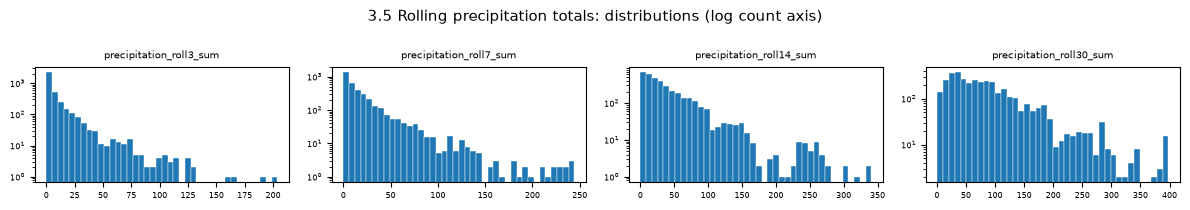

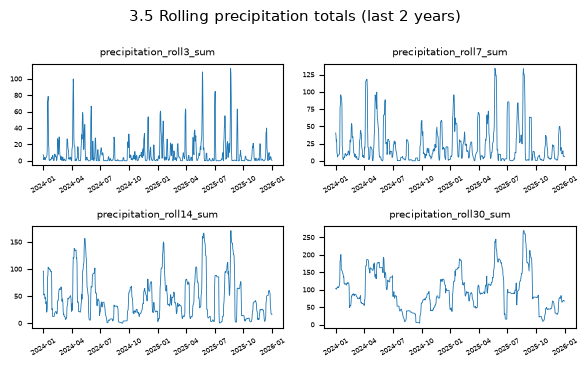

In [17]:
precipitation_frame = rolling_precipitation(daily)

columns = list(precipitation_frame.columns)
fig, axes = _panel_grid(len(columns), 4, panel_height=2.1)
for axis, column in zip(axes, columns):
    axis.hist(precipitation_frame[column].dropna(), bins=40, color="tab:blue",
              edgecolor="white", linewidth=0.3)
    axis.set_yscale("log")
    axis.set_title(column, fontsize=7)
    axis.tick_params(labelsize=6)
fig.suptitle("3.5 Rolling precipitation totals: distributions (log count axis)", fontsize=11)
fig.tight_layout()
save_figure(fig, "features-35-precipitation-dist")

series_grid(precipitation_frame, "3.5 Rolling precipitation totals",
            "features-35-precipitation-series", ncols=2)
plt.show()

### 3.6 Rolling gust maxima

Gusts are summarised with a maximum rather than a mean, because the meteorologically meaningful
quantity is the strongest gust the window contained, not its typical value. Averaging would
dilute exactly the extreme these features exist to capture.

| Column | What it is | Why it is included |
| --- | --- | --- |
| `wind_gusts_10m_roll3_max` | Strongest gust over *t*−2 to *t*, km/h | Flags a recent convective or frontal event. Such systems typically take more than three days to clear, so the marker remains relevant across the comfort horizon. |
| `wind_gusts_10m_roll7_max` | Strongest gust in the week ending *t*, km/h | Distinguishes a genuinely stormy week from a calm one; at the 7-day hazard horizon this is the closest thing to a same-scale reference. |
| `wind_gusts_10m_roll14_max` | Strongest gust in the fortnight ending *t*, km/h | Medium-term storminess of the current pattern. |
| `wind_gusts_10m_roll30_max` | Strongest gust in the month ending *t*, km/h | Seasonal-scale windiness; slow-moving and close to a local climatology term. |

These features are motivated most directly by the hazard task, where gusts carry a 0.30 weight.
They are retained for the comfort task as well because storminess suppresses comfort through the
cloud, rain and wind components together — which is precisely the kind of cross-target reuse the
shared feature matrix exists to allow.

In [18]:
def rolling_gusts(frame: pd.DataFrame) -> pd.DataFrame:
    """Return peak gusts over windows ending on *t*, or an empty frame if gusts are absent."""
    if "wind_gusts_10m" not in MODEL_VARIABLES:
        return pd.DataFrame(index=frame.index)
    return pd.DataFrame(
        {f"wind_gusts_10m_roll{window}_max":
         frame["wind_gusts_10m"].rolling(window, min_periods=window).max()
         for window in ROLLING_WINDOWS},
        index=frame.index,
    )


preview = rolling_gusts(daily)
print(f"3.6 rolling gust maxima: {preview.shape[1]} columns"
      f"{'' if preview.shape[1] else ' (wind_gusts_10m unavailable)'}")
preview.tail(3)

3.6 rolling gust maxima: 4 columns


,wind_gusts_10m_roll3_max,wind_gusts_10m_roll7_max,wind_gusts_10m_roll14_max,wind_gusts_10m_roll30_max
time,,,,
2025-12-29,56.50,70.60,70.60,79.20
2025-12-30,56.50,56.50,70.60,79.20
2025-12-31,40.70,56.50,70.60,79.20


#### Visual check

Peak gusts should form a series of plateaus: a single storm sets the maximum, which then holds
until it drops out of the window. Longer windows plateau for longer. Seeing that staircase shape
confirms the maximum is behaving as intended rather than averaging the extremes away.

The distributions are expected to shift right as the window lengthens, since a longer window has
more opportunities to contain a strong gust. The 100 km/h reference line shows where
`wind_hazard` would saturate; if even the 30-day maximum rarely approaches it, the wind term is
operating well below its cap for almost the whole record.

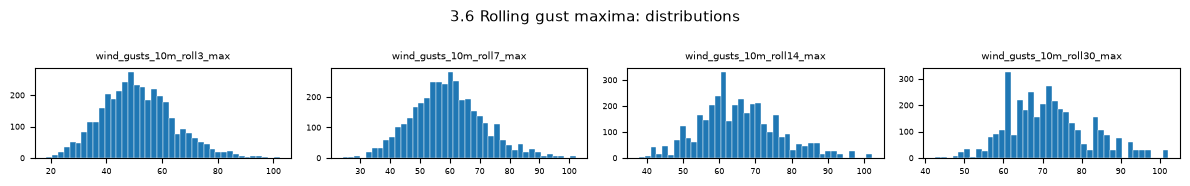

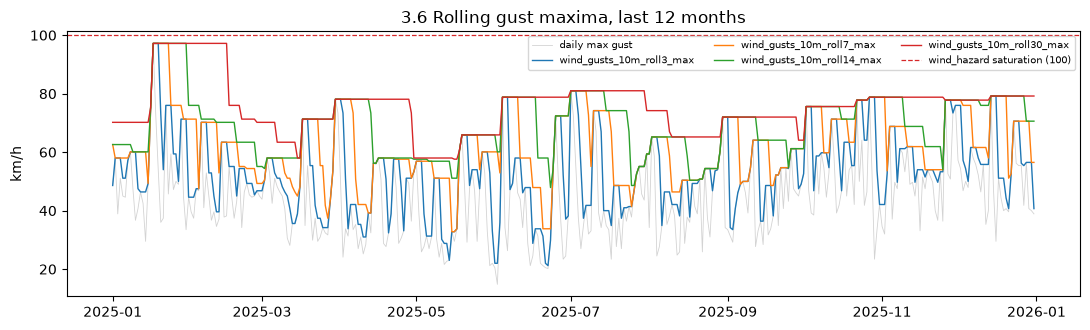

In [19]:
gust_frame = rolling_gusts(daily)
if gust_frame.empty:
    print("wind_gusts_10m is unavailable; no gust features to plot.")
else:
    distribution_grid(gust_frame, "3.6 Rolling gust maxima: distributions",
                      "features-36-gusts-dist", ncols=4)
    recent = gust_frame.loc[gust_frame.index > gust_frame.index.max() - pd.DateOffset(years=1)]
    fig, axis = plt.subplots(figsize=(11, 3.4))
    axis.plot(recent.index, daily["wind_gusts_10m"].reindex(recent.index),
              color="lightgrey", lw=0.6, label="daily max gust")
    for column in gust_frame.columns:
        axis.plot(recent.index, recent[column], lw=1.0, label=column)
    axis.axhline(100, color="tab:red", lw=0.9, ls="--", label="wind_hazard saturation (100)")
    axis.set(title="3.6 Rolling gust maxima, last 12 months", ylabel="km/h")
    axis.legend(fontsize=7, ncol=3)
    fig.tight_layout()
    save_figure(fig, "features-36-gusts-series")
plt.show()

### 3.7 Short-term deltas

The change in a variable between *t*−k and *t*, for k of 1 and 3 days.

A tree ensemble cannot form a difference between two columns on its own — it splits on one
feature at a time, so `temperature_2m` and `temperature_2m_lag3` being both present does not let
it act on the gap between them without spending many splits approximating it. Providing the
difference directly makes the trend available in a single split.

Two step sizes are used: 1 day for the immediate direction, and 3 days for the trend across the
current synoptic system.

| Column | What it is | Why it is included |
| --- | --- | --- |
| `temperature_2m_delta1` | *t* minus *t*−1 temperature, °C | Yesterday-to-today warming or cooling. Large negative values typically follow a cool change. |
| `temperature_2m_delta3` | *t* minus *t*−3 temperature, °C | Sustained thermal trend, less sensitive to a single unusual day. |
| `cci_delta1` | *t* minus *t*−1 CCI | Whether comfort is improving or deteriorating right now. |
| `cci_delta3` | *t* minus *t*−3 CCI | The direction of the current comfort regime; the closest available thing to a momentum term on the regression target. |
| `whi_delta1` | *t* minus *t*−1 WHI | Whether hazard is building or easing. A rising WHI approaching 25 is the state in which the class is most likely to change. |
| `whi_delta3` | *t* minus *t*−3 WHI | Hazard momentum across the current system. |
| `pressure_msl_delta1` | *t* minus *t*−1 pressure, hPa | Built only if pressure was ingested. The standard short-range frontal indicator: a sharp fall precedes wind, cloud and rain, which move both indices at once. |
| `pressure_msl_delta3` | *t* minus *t*−3 pressure, hPa | Distinguishes a deepening system from a transient wobble in the barometer. |

Of all engineered features, the pressure deltas are the most likely to add information the
formula inputs cannot supply, because they describe the atmosphere's *tendency* rather than its
current state. Whether they earn their place is tested in the modelling ablations rather than
assumed here.

In [20]:
# Pressure is included only when ingested; it is the most informative delta available.
DELTA_BASE = [
    column for column in ["temperature_2m", "cci", "whi", "pressure_msl"]
    if column in MODEL_VARIABLES or column in MODEL_INDEX_COLUMNS
]
DELTA_STEPS = (1, 3)


def short_term_deltas(frame: pd.DataFrame) -> pd.DataFrame:
    """Return the change in each base variable between *t*-k and *t*."""
    return pd.DataFrame(
        {f"{column}_delta{step}": frame[column] - frame[column].shift(step)
         for column in DELTA_BASE for step in DELTA_STEPS},
        index=frame.index,
    )


preview = short_term_deltas(daily)
print(f"3.7 short-term deltas: {preview.shape[1]} columns "
      f"({len(DELTA_BASE)} variables x {len(DELTA_STEPS)} steps)")
preview.tail(3)

3.7 short-term deltas: 6 columns (3 variables x 2 steps)


,temperature_2m_delta1,temperature_2m_delta3,cci_delta1,cci_delta3,whi_delta1,whi_delta3
time,,,,,,
2025-12-29,0.09,2.36,7.77,18.94,-12.38,-19.46
2025-12-30,0.48,1.74,-3.73,3.90,3.87,-2.36
2025-12-31,0.67,1.24,-10.15,-6.11,9.83,1.32


#### Visual check

Deltas should be centred on zero and roughly symmetric: over a long record the atmosphere warms
as often as it cools. A visible offset would indicate a trend or a construction error.

The three-day deltas should be wider than the one-day deltas, since more can change over a
longer interval. The tails are the interesting part — the extreme negative
`temperature_2m_delta1` values are Sydney's southerly busters, and these are exactly the abrupt
transitions that make the following days hard to predict from persistence alone.

The scatter panels relate each driver delta to the concurrent change in each index, showing
whether the mechanism the feature is meant to capture is actually present in the data.

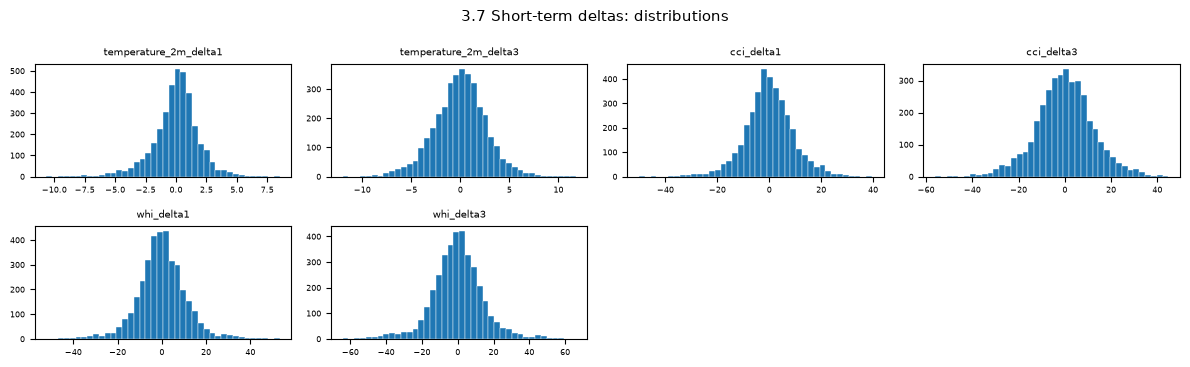

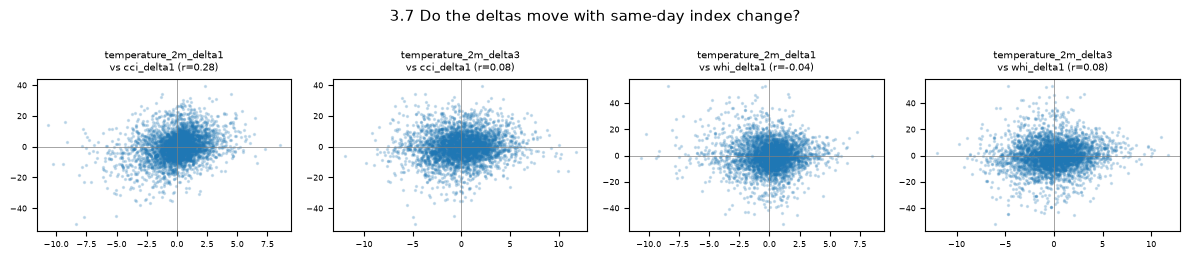

In [21]:
delta_frame = short_term_deltas(daily)
distribution_grid(delta_frame, "3.7 Short-term deltas: distributions",
                  "features-37-deltas-dist", ncols=4)

drivers = [c for c in delta_frame.columns if not c.startswith(("cci_", "whi_"))]
responses = [c for c in ("cci_delta1", "whi_delta1") if c in delta_frame.columns]
pairs = [(driver, response) for response in responses for driver in drivers]
fig, axes = _panel_grid(len(pairs), 4, panel_height=2.6)
for axis, (driver, response) in zip(axes, pairs):
    axis.scatter(delta_frame[driver], delta_frame[response], s=2, alpha=0.2, color="tab:blue")
    axis.axhline(0, color="grey", lw=0.5)
    axis.axvline(0, color="grey", lw=0.5)
    correlation = delta_frame[driver].corr(delta_frame[response])
    axis.set_title(f"{driver}\nvs {response} (r={correlation:.2f})", fontsize=7)
    axis.tick_params(labelsize=6)
fig.suptitle("3.7 Do the deltas move with same-day index change?", fontsize=11)
fig.tight_layout()
save_figure(fig, "features-37-deltas-vs-indices")
plt.show()

### 3.8 Seasonal position

Day-of-year encoded as a sine and cosine pair.

Sydney's comfort and hazard distributions both differ sharply between seasons, so the calendar
position carries real predictive weight independently of current conditions: a 25°C day in
October and a 25°C day in February sit in different regimes and have different likely successors.
The effect is larger for the hazard model than the comfort model, because at a 7-day horizon
current conditions have largely decayed and seasonal base rates are a larger share of what is
left to predict.

The obvious encoding — day-of-year as an integer from 1 to 365 — introduces an artificial
discontinuity at the year boundary, where 31 December and 1 January are one day apart in reality
but 364 apart numerically. A tree would have to spend splits repairing that. Projecting the
angle onto a sine and cosine pair removes the seam: the two columns together locate the day on a
circle, so late December and early January are correctly adjacent.

| Column | What it is | Why it is included |
| --- | --- | --- |
| `doy_sin` | `sin(2 x pi x day_of_year / 365.25)` | One coordinate of the calendar position on the annual cycle. |
| `doy_cos` | `cos(2 x pi x day_of_year / 365.25)` | The other coordinate. Both are required: either alone is ambiguous, since one value maps to two dates in the year. |

`365.25` is used rather than `365` so that the phase does not drift across leap years.

These are the only features that are not derived from observations at all. They are computable
for any future date, which makes them the one part of the feature vector the API can always
construct without an archive lookup.

In [22]:
def seasonal_position(frame: pd.DataFrame) -> pd.DataFrame:
    """Return day-of-year as a sine/cosine pair, avoiding the 31 Dec to 1 Jan discontinuity."""
    day_of_year = frame.index.dayofyear
    angle = 2 * np.pi * day_of_year / 365.25
    return pd.DataFrame(
        {"doy_sin": np.sin(angle), "doy_cos": np.cos(angle)}, index=frame.index
    )


preview = seasonal_position(daily)
print(f"3.8 seasonal position: {preview.shape[1]} columns")
preview.tail(3)

3.8 seasonal position: 2 columns


,doy_sin,doy_cos
time,,
2025-12-29,-0.04,1.00
2025-12-30,-0.02,1.00
2025-12-31,-0.00,1.00


#### Visual check

The first figure plots both encodings against day-of-year and shows the pair traced as a circle.
The circle is the point of the encoding: 31 December and 1 January sit adjacent on it, whereas an
integer day-of-year would place them 364 apart and force the model to spend splits repairing the
seam.

The remaining figures are the justification for including seasonality at all. They plot mean CCI
and mean WHI by day-of-year across the record, and the share of days in each hazard class by
month. If the targets vary systematically through the year, the calendar position carries
predictive information that no same-day observation supplies, and the encoding earns its place.
Flat curves would mean these two columns are dead weight.

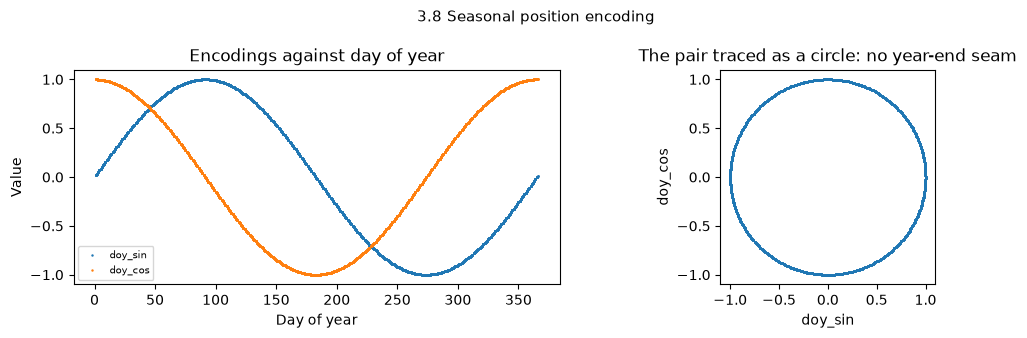

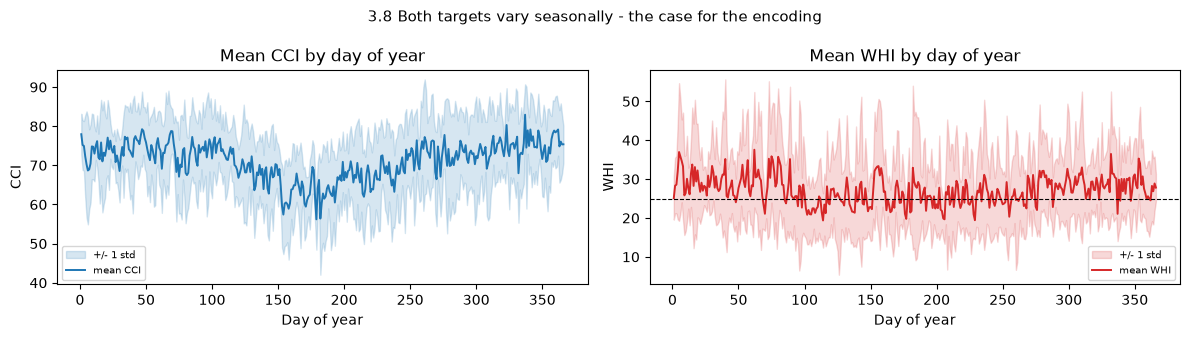

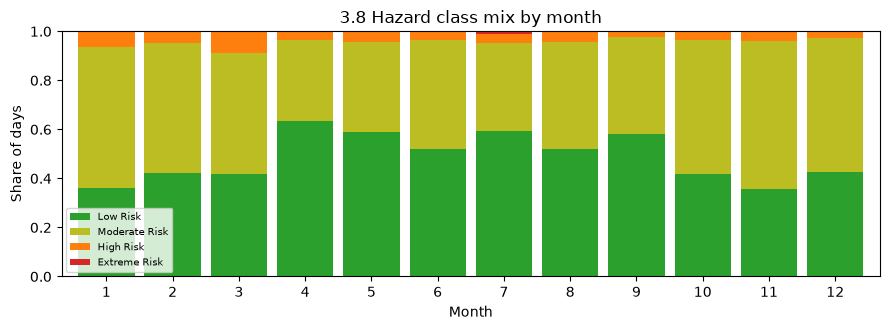

In [23]:
seasonal_frame = seasonal_position(daily)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
day_of_year = daily.index.dayofyear
axes[0].plot(day_of_year, seasonal_frame["doy_sin"], ".", ms=1.5, label="doy_sin")
axes[0].plot(day_of_year, seasonal_frame["doy_cos"], ".", ms=1.5, label="doy_cos")
axes[0].set(title="Encodings against day of year", xlabel="Day of year", ylabel="Value")
axes[0].legend(fontsize=7)
axes[1].plot(seasonal_frame["doy_sin"], seasonal_frame["doy_cos"], ".", ms=1.5, color="tab:blue")
axes[1].set(title="The pair traced as a circle: no year-end seam",
            xlabel="doy_sin", ylabel="doy_cos")
axes[1].set_aspect("equal")
fig.suptitle("3.8 Seasonal position encoding", fontsize=11)
fig.tight_layout()
save_figure(fig, "features-38-seasonal-encoding")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for axis, (column, colour) in zip(axes, [("cci", "tab:blue"), ("whi", "tab:red")]):
    profile = daily.groupby(daily.index.dayofyear)[column].agg(["mean", "std"])
    axis.fill_between(profile.index, profile["mean"] - profile["std"],
                      profile["mean"] + profile["std"], color=colour, alpha=0.18,
                      label="+/- 1 std")
    axis.plot(profile.index, profile["mean"], color=colour, lw=1.4, label=f"mean {column.upper()}")
    axis.set(title=f"Mean {column.upper()} by day of year", xlabel="Day of year",
             ylabel=column.upper())
    axis.legend(fontsize=7)
axes[1].axhline(25, color="black", lw=0.8, ls="--")
fig.suptitle("3.8 Both targets vary seasonally - the case for the encoding", fontsize=11)
fig.tight_layout()
save_figure(fig, "features-38-seasonal-target-profiles")

monthly_mix = (
    pd.crosstab(daily.index.month, daily["whc"], normalize="index")
    .rename(columns=WHC_LABELS)
)
fig, axis = plt.subplots(figsize=(9, 3.4))
monthly_mix.plot.bar(stacked=True, ax=axis, width=0.85,
                     color=["tab:green", "tab:olive", "tab:orange", "tab:red"][:monthly_mix.shape[1]])
axis.set(title="3.8 Hazard class mix by month", xlabel="Month", ylabel="Share of days")
axis.legend(fontsize=7)
axis.tick_params(labelrotation=0)
fig.tight_layout()
save_figure(fig, "features-38-hazard-class-by-month", subdir="weather_hazard")
plt.show()

### 3.9 Assembling the feature matrix

The eight families are composed into a single builder. Keeping this as one function matters for
three reasons beyond tidiness:

- section 6 calls it on a **truncated** series to verify that no column looks ahead, which is
  only a valid test if the production path uses the same code;
- the API must construct an identical feature vector at request time for both endpoints, so this
  function is the natural candidate to move into the custom package and import in all three
  places;
- both targets consume the same matrix, so a change made for one task cannot silently diverge
  from the other.

The group mapping is returned alongside the matrix and written to both metadata files, so each
modelling notebook can run an ablation over families — persistence only, then same-day, then
history, then seasonality — and quantify what each contributes rather than presenting a single
undifferentiated model.

In [24]:
def build_features(frame: pd.DataFrame) -> tuple[pd.DataFrame, dict[str, list[str]]]:
    """Build the full leakage-safe feature matrix from a gapless daily frame.

    Every column depends only on observations dated on or before its own index date, which makes
    the matrix valid for both the +3 day comfort target and the +7 day hazard target.

    Parameters
    ----------
    frame
        Daily frame with a gapless ``DatetimeIndex``, the formula inputs, the component scores
        and both indices.

    Returns
    -------
    tuple
        The feature matrix, and a mapping of family name to the columns it contributed.
    """
    families = {
        "same_day_observations": same_day_observations(frame),
        "same_day_indices": same_day_indices(frame),
        "lags": lagged_observations(frame),
        "rolling_statistics": rolling_statistics(frame),
        "rolling_precipitation": rolling_precipitation(frame),
        "rolling_gusts": rolling_gusts(frame),
        "deltas": short_term_deltas(frame),
        "seasonal": seasonal_position(frame),
    }
    families = {name: part for name, part in families.items() if not part.empty}
    matrix = pd.concat(families.values(), axis=1)
    groups = {name: list(part.columns) for name, part in families.items()}
    return matrix, groups


features, FEATURE_GROUPS = build_features(daily)
FEATURE_COLUMNS = list(features.columns)

if features.columns.duplicated().any():
    duplicated = list(features.columns[features.columns.duplicated()])
    raise ValueError(f"Duplicate feature names: {duplicated}")

FAMILY_OF = {column: family for family, columns in FEATURE_GROUPS.items() for column in columns}

print(f"Engineered {len(FEATURE_COLUMNS)} shared features across {len(FEATURE_GROUPS)} "
      "families:\n")
inventory = pd.DataFrame({"columns": {name: len(cols) for name, cols in FEATURE_GROUPS.items()}})
inventory["share"] = inventory["columns"] / inventory["columns"].sum()
print(inventory.to_string(formatters={"share": "{:.1%}".format}))
features.tail(3).iloc[:, :6]

Engineered 105 shared features across 8 families:

                       columns share
same_day_observations        6  5.7%
same_day_indices            11 10.5%
lags                        32 30.5%
rolling_statistics          40 38.1%
rolling_precipitation        4  3.8%
rolling_gusts                4  3.8%
deltas                       6  5.7%
seasonal                     2  1.9%


,temperature_2m,relative_humidity_2m,wind_speed_10m,cloud_cover,precipitation,wind_gusts_10m
time,,,,,,
2025-12-29,18.32,61.38,8.90,20.29,0.00,40.70
2025-12-30,18.80,64.29,8.35,41.67,0.00,40.00
2025-12-31,19.47,73.04,8.35,91.79,0.40,38.90


#### Feature matrix overview

Two whole-matrix views. The completeness bar chart shows how many rows each family loses to its
warm-up, which is what drives the row count dropped in section 4: the 30-day rolling windows are
the binding constraint.

The correlation heatmap groups features by family. Dense blocks of near-perfect correlation
indicate redundancy — most likely among the rolling means of adjacent window lengths, and
between each comfort score and its hazard counterpart — which is useful context when reading
feature importances later, since correlated predictors split their importance between them and
can each look individually unimportant.

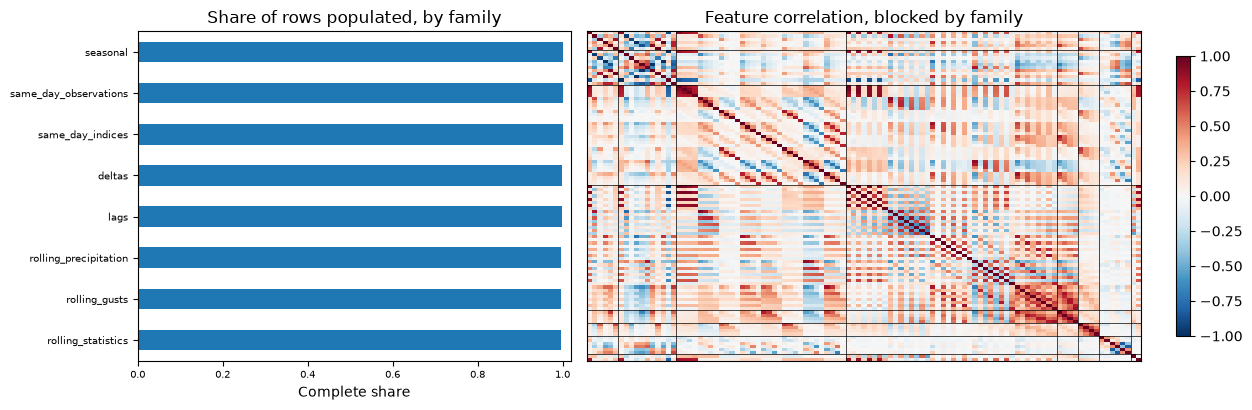

In [25]:
completeness = features.notna().mean().groupby(
    [FAMILY_OF[column] for column in features.columns]
).mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.6]})
completeness.sort_values().plot.barh(ax=axes[0], color="tab:blue")
axes[0].set(title="Share of rows populated, by family", xlabel="Complete share", xlim=(0, 1.02))
axes[0].tick_params(labelsize=7)

ordered = [column for family in FEATURE_GROUPS for column in FEATURE_GROUPS[family]]
correlation = features[ordered].corr()
image = axes[1].imshow(correlation, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
boundary = 0
for family, columns in FEATURE_GROUPS.items():
    boundary += len(columns)
    axes[1].axhline(boundary - 0.5, color="black", lw=0.5)
    axes[1].axvline(boundary - 0.5, color="black", lw=0.5)
axes[1].set(title="Feature correlation, blocked by family", xticks=[], yticks=[])
fig.colorbar(image, ax=axes[1], shrink=0.85)
fig.tight_layout()
save_figure(fig, "features-39-matrix-overview")
plt.show()

## 4. Target alignment

The feature matrix is shared; the labels are not. Two target blocks are built from it.

| Block | Columns | Meaning |
| --- | --- | --- |
| Comfort | `cci_t1`, `cci_t2`, `cci_t3` | CCI observed on *t*+1, *t*+2 and *t*+3 |
| Hazard | `whc_t7` | Hazard class observed on *t*+7 (the model target) |
| Hazard (auxiliary) | `whi_t7` | The continuous index behind `whc_t7` |

All three comfort horizons sit on the same row so the comfort notebook can train three models
against an identical feature matrix and identical splits, making the cross-horizon comparison a
fair one. The hazard block carries a single horizon because the brief specifies exactly +7 days.

**`whi_t7` is not a feature.** It is written to the hazard files so that misclassifications can
be examined against their distance from a class boundary — a day at WHI 24.8 predicted Moderate
is a different kind of error from one at WHI 12 — and so that an ordinal or regression-then-
threshold approach can be explored as an alternative framing. It is excluded from
`feature_columns` in the metadata and must be dropped before fitting. Using it as a predictor
would be direct leakage of the label.

Rows are dropped when the 30-day warm-up is incomplete, when any feature or target is missing
(a masked incomplete day), or at the tail of the series where the future is unobserved. Because
the horizons differ, the two datasets lose different numbers of tail rows and are therefore
built separately rather than sharing one row filter.

Alignment is verified by value: each target is compared against the index looked up at
`feature_date + horizon`. Asserting that `feature_date + h` is later than `feature_date` would
be true by construction and would not detect a positional shift landing on the wrong row.

In [26]:
cci_targets = pd.DataFrame(
    {f"cci_t{horizon}": daily["cci"].shift(-horizon) for horizon in CCI_HORIZONS},
    index=daily.index,
)
CCI_TARGET_COLUMNS = list(cci_targets.columns)

whc_targets = pd.DataFrame(
    {
        f"whc_t{WHC_HORIZON}": daily["whc"].shift(-WHC_HORIZON),
        f"whi_t{WHC_HORIZON}": daily["whi"].shift(-WHC_HORIZON),
    },
    index=daily.index,
)
WHC_TARGET_COLUMN = f"whc_t{WHC_HORIZON}"
WHC_AUXILIARY_COLUMN = f"whi_t{WHC_HORIZON}"


def verify_alignment(target: pd.Series, source: pd.Series, horizon: int, name: str) -> None:
    """Fail loudly if ``target`` is not ``source`` observed ``horizon`` days later."""
    expected = source.reindex(target.index + pd.Timedelta(days=horizon)).to_numpy(dtype=float)
    actual = target.to_numpy(dtype=float)
    if not np.array_equal(actual, expected, equal_nan=True):
        raise AssertionError(f"{name} does not match the source value on that date.")


for horizon in CCI_HORIZONS:
    verify_alignment(cci_targets[f"cci_t{horizon}"], daily["cci"], horizon, f"cci_t{horizon}")
verify_alignment(whc_targets[WHC_TARGET_COLUMN], daily["whc"], WHC_HORIZON, WHC_TARGET_COLUMN)
verify_alignment(whc_targets[WHC_AUXILIARY_COLUMN], daily["whi"], WHC_HORIZON,
                 WHC_AUXILIARY_COLUMN)
print("Alignment verified: every target equals the index observed on feature_date + horizon.")

sample = pd.concat([daily[["cci", "whi", "whc"]], cci_targets, whc_targets], axis=1)
print("\nWorked example (the +7 day class on the first row is the 'whc' value eight rows down):")
print(sample.head(8).to_string())

Alignment verified: every target equals the index observed on feature_date + horizon.

Worked example (the +7 day class on the first row is the 'whc' value eight rows down):
             cci   whi  whc  cci_t1  cci_t2  cci_t3  whc_t7  whi_t7
time                                                               
2016-01-01 78.20 24.00    0   72.52   72.94   54.19       0   20.49
2016-01-02 72.52 31.15    1   72.94   54.19   47.57       0   17.98
2016-01-03 72.94 34.03    1   54.19   47.57   45.93       0   13.93
2016-01-04 54.19 46.78    1   47.57   45.93   72.47       0   12.88
2016-01-05 47.57 63.53    2   45.93   72.47   80.40       1   29.79
2016-01-06 45.93 64.13    2   72.47   80.40   80.37       0   12.06
2016-01-07 72.47 29.24    1   80.40   80.37   85.67       1   35.11
2016-01-08 80.40 20.49    0   80.37   85.67   80.50       2   54.39


In [27]:
def assemble_dataset(feature_matrix: pd.DataFrame, targets: pd.DataFrame, horizon: int,
                     label: str) -> pd.DataFrame:
    """Join features to targets and apply the warm-up, missingness and production filters.

    Parameters
    ----------
    feature_matrix
        The shared feature matrix.
    targets
        Target columns already shifted to the required horizon.
    horizon
        Largest forecast horizon in ``targets``, in days. Used to hold the reserved production
        period out of the target column as well as the feature dates.
    label
        Name used in the printed summary.

    Returns
    -------
    pd.DataFrame
        Rows whose features are complete and whose targets are observed and pre-2026.
    """
    frame = feature_matrix.join(targets)

    # The first WARMUP_DAYS rows cannot have complete rolling windows.
    warmup_cutoff = frame.index.min() + pd.Timedelta(days=WARMUP_DAYS - 1)
    frame = frame.loc[frame.index > warmup_cutoff]

    before = len(frame)
    frame = frame.dropna()
    dropped = before - len(frame)

    # The production cutoff is embargoed as well as filtered. Restricting only the feature date
    # would leave the final rows carrying targets dated in 2026, which would draw the reserved
    # production period into the test set through the target column.
    frame = frame.loc[frame.index < PRODUCTION_CUTOFF - pd.Timedelta(days=horizon)]
    frame.index.name = "feature_date"

    latest_target = frame.index.max() + pd.Timedelta(days=horizon)
    if latest_target >= PRODUCTION_CUTOFF:
        raise AssertionError(f"Target dated {latest_target:%Y-%m-%d} falls in the production "
                             "period.")
    print(f"{label}: dropped {dropped:,} row(s) with missing features or targets "
          f"(masked days and the final {horizon} dates)")
    print(f"{'':<{len(label)}}  window {frame.index.min():%Y-%m-%d} to "
          f"{frame.index.max():%Y-%m-%d} ({len(frame):,} rows); "
          f"latest target {latest_target:%Y-%m-%d}\n")
    return frame


cci_dataset = assemble_dataset(features, cci_targets, CCI_EMBARGO, "Comfort (CCI)")
whc_dataset = assemble_dataset(features, whc_targets, WHC_HORIZON, "Hazard (WHC)")

whc_dataset[WHC_TARGET_COLUMN] = whc_dataset[WHC_TARGET_COLUMN].astype("int64")

print(f"Shared features: {len(FEATURE_COLUMNS)}")
print(f"Comfort targets: {CCI_TARGET_COLUMNS}")
print(f"Hazard target  : {WHC_TARGET_COLUMN} (auxiliary, not a feature: {WHC_AUXILIARY_COLUMN})")
print(f"\nThe hazard dataset is {len(cci_dataset) - len(whc_dataset)} rows shorter than the "
      "comfort dataset,\nbecause a 7-day horizon consumes four more days at the end of the "
      "record than a 3-day one.")

Comfort (CCI): dropped 3 row(s) with missing features or targets (masked days and the final 3 dates)
               window 2016-01-31 to 2025-12-28 (3,620 rows); latest target 2025-12-31

Hazard (WHC): dropped 7 row(s) with missing features or targets (masked days and the final 7 dates)
              window 2016-01-31 to 2025-12-24 (3,616 rows); latest target 2025-12-31

Shared features: 105
Comfort targets: ['cci_t1', 'cci_t2', 'cci_t3']
Hazard target  : whc_t7 (auxiliary, not a feature: whi_t7)

The hazard dataset is 4 rows shorter than the comfort dataset,
because a 7-day horizon consumes four more days at the end of the record than a 3-day one.


### 4.1 Feature strength against the comfort target

With the targets aligned, every feature can be related to what it is meant to predict. This is
the last diagnostic before splitting, and it produces three things the report needs.

**Correlation by horizon.** For each feature, the Pearson correlation with `cci_t1`, `cci_t2`
and `cci_t3`. The expected pattern is a systematic weakening as the horizon lengthens, since
atmospheric predictability decays; features that hold their correlation at *t*+3 are the ones
carrying genuine forecast signal rather than persistence.

**Ranked feature strength.** The top features by absolute correlation with `cci_t3`, the hardest
comfort horizon. Correlation is univariate and linear, so it will understate features that
matter only in interaction — it is a screening view, not a substitute for the model's own
importances.

**Scatter panels.** The relationship for the strongest features, which exposes non-linearity that
a correlation coefficient reduces to a single misleading number.

Note that this analysis is run on the **full modelling window**, before the split. It is used to
describe the data and to motivate the feature set, never to select features — doing the latter
on data that includes the test period would leak test information into the model through the
choice of columns.

Mean absolute correlation with each comfort target, by family:
                       cci_t1  cci_t2  cci_t3
family                                       
deltas                   0.16    0.07    0.03
lags                     0.13    0.12    0.10
rolling_gusts            0.07    0.09    0.09
rolling_precipitation    0.15    0.09    0.06
rolling_statistics       0.19    0.15    0.13
same_day_indices         0.31    0.19    0.14
same_day_observations    0.24    0.15    0.12
seasonal                 0.17    0.18    0.18


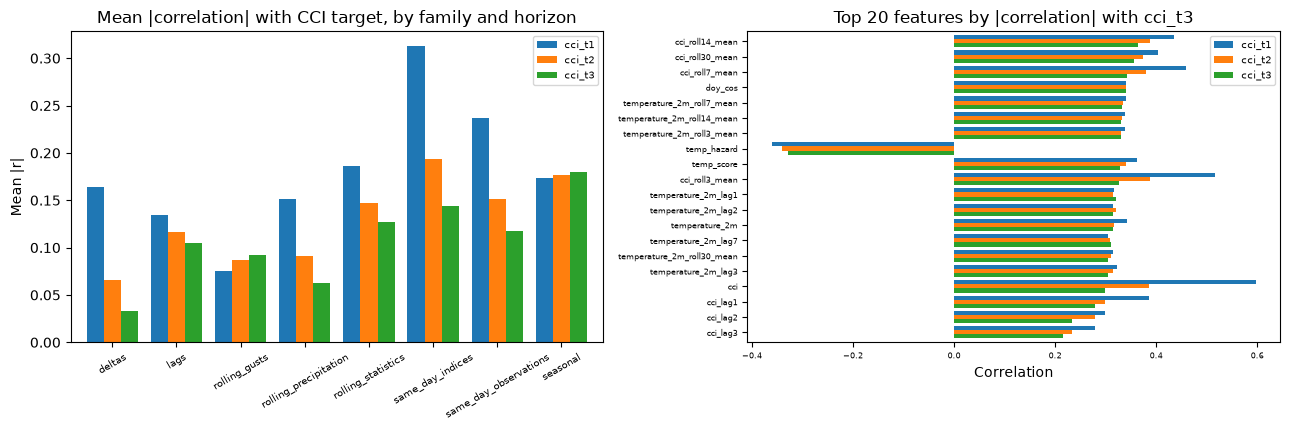

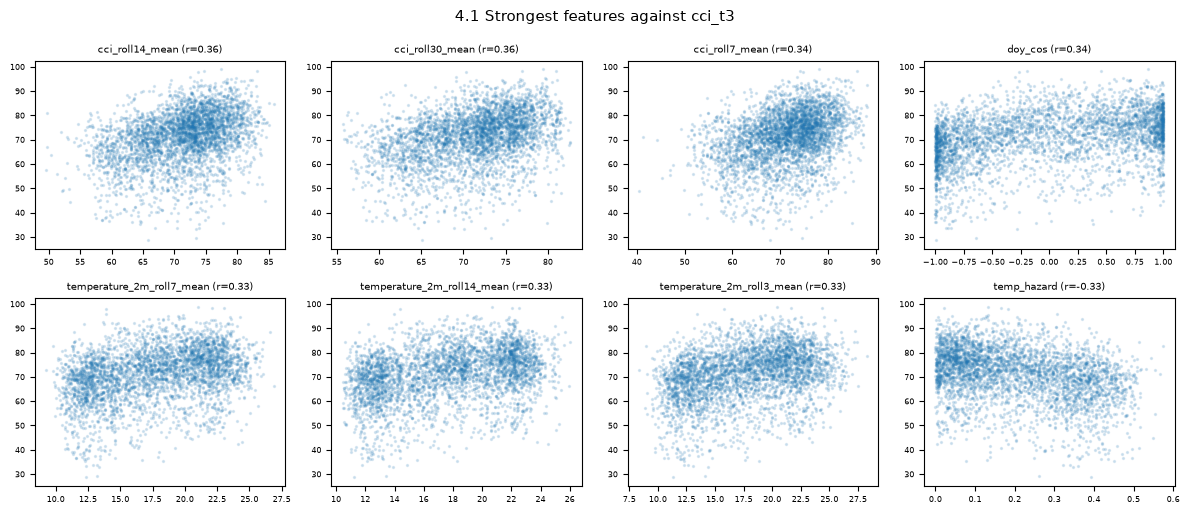

In [28]:
cci_correlation = pd.DataFrame(
    {target: cci_dataset[FEATURE_COLUMNS].corrwith(cci_dataset[target])
     for target in CCI_TARGET_COLUMNS}
)
cci_correlation["family"] = [FAMILY_OF[column] for column in cci_correlation.index]

family_strength = (
    cci_correlation.groupby("family")[CCI_TARGET_COLUMNS].apply(lambda g: g.abs().mean())
)
print("Mean absolute correlation with each comfort target, by family:")
print(family_strength.to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
family_strength.plot.bar(ax=axes[0], width=0.8)
axes[0].set(title="Mean |correlation| with CCI target, by family and horizon",
            ylabel="Mean |r|", xlabel="")
axes[0].tick_params(axis="x", labelrotation=30, labelsize=7)
axes[0].legend(fontsize=7)

top_cci = cci_correlation["cci_t3"].abs().sort_values(ascending=False).head(20).index
cci_correlation.loc[top_cci, CCI_TARGET_COLUMNS].plot.barh(ax=axes[1], width=0.8)
axes[1].invert_yaxis()
axes[1].set(title="Top 20 features by |correlation| with cci_t3", xlabel="Correlation")
axes[1].tick_params(labelsize=6)
axes[1].legend(fontsize=7)
fig.tight_layout()
save_figure(fig, "features-41-cci-target-correlation", subdir="comfort_climate")

strongest = list(top_cci[:8])
fig, axes = _panel_grid(len(strongest), 4, panel_height=2.6)
for axis, column in zip(axes, strongest):
    axis.scatter(cci_dataset[column], cci_dataset["cci_t3"], s=2, alpha=0.15, color="tab:blue")
    correlation = cci_dataset[column].corr(cci_dataset["cci_t3"])
    axis.set_title(f"{column} (r={correlation:.2f})", fontsize=7)
    axis.tick_params(labelsize=6)
fig.suptitle("4.1 Strongest features against cci_t3", fontsize=11)
fig.tight_layout()
save_figure(fig, "features-41-cci-top-scatter", subdir="comfort_climate")
plt.show()

### 4.2 Feature strength against the hazard target

Correlation is the wrong screening statistic for a class label: it assumes a linear relationship
with a numeric outcome, and the hazard classes are ordinal categories. Two class-appropriate
views are used instead.

**Eta squared (η²).** The share of a feature's variance that lies *between* hazard classes
rather than within them. It ranges from 0 (class means identical, the feature separates nothing)
to 1 (classes perfectly separated on that feature). Unlike correlation it makes no linearity
assumption and handles more than two classes, and unlike mutual information it needs no binning
choice. It is still univariate, so the same caveat applies: it will understate features that
matter only in interaction.

**Class-conditional means.** For the strongest features, the mean value within each class. This
shows the *direction* and *shape* of the separation — whether the feature rises monotonically
with hazard, as an ordinal target would suggest it should, or separates only the extremes.

Classes with very few days produce unstable means, so the counts are printed alongside. As in
4.1, this analysis is descriptive; it is run before the split for documentation only and is
never used to select columns.

Class counts in the modelling window:
            category  rows  share
class                            
0           Low Risk  1763 48.76%
1      Moderate Risk  1696 46.90%
2          High Risk   149  4.12%
3       Extreme Risk     8  0.22%

Mean eta-squared against the hazard class, by family:
seasonal                0.014
rolling_statistics      0.005
rolling_gusts           0.004
same_day_indices        0.004
lags                    0.004
same_day_observations   0.004
rolling_precipitation   0.001
deltas                  0.001


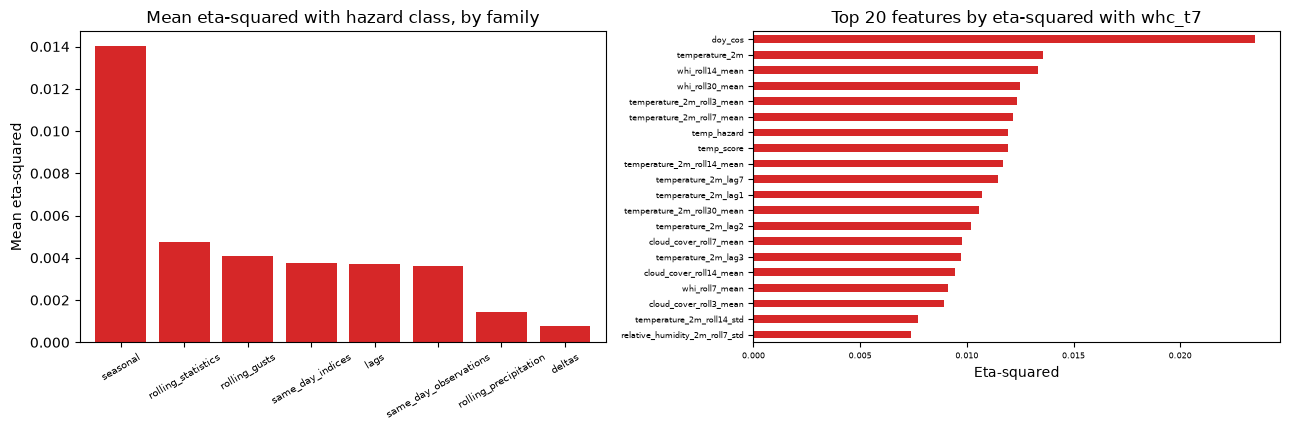

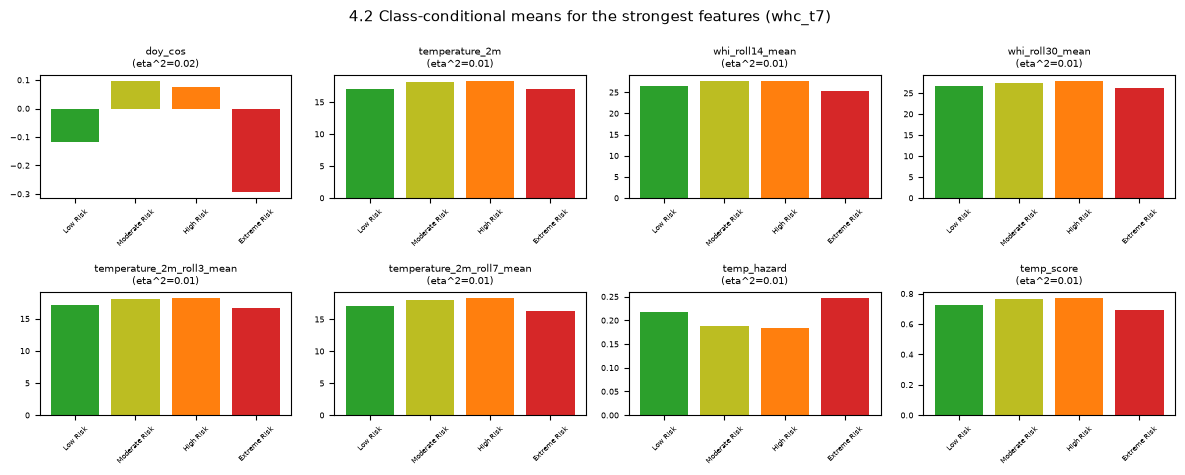

In [29]:
def eta_squared(frame: pd.DataFrame, feature_columns: list[str], label_column: str) -> pd.Series:
    """Return the between-class share of variance for each feature.

    Interpreted as the proportion of each feature's total variance explained by the class label:
    0 means the class means are identical, 1 means the classes are perfectly separated.
    """
    labels = frame[label_column]
    values = frame[feature_columns]
    overall_mean = values.mean()
    total_ss = ((values - overall_mean) ** 2).sum()
    group_means = values.groupby(labels).mean()
    group_sizes = labels.value_counts().sort_index()
    between_ss = ((group_means - overall_mean) ** 2).mul(group_sizes, axis=0).sum()
    return (between_ss / total_ss.replace(0, np.nan)).sort_values(ascending=False)


whc_strength = eta_squared(whc_dataset, FEATURE_COLUMNS, WHC_TARGET_COLUMN)
whc_strength_by_family = (
    whc_strength.groupby([FAMILY_OF[column] for column in whc_strength.index]).mean()
    .sort_values(ascending=False)
)

print("Class counts in the modelling window:")
counts = whc_dataset[WHC_TARGET_COLUMN].value_counts().sort_index()
print(pd.DataFrame({"category": [WHC_LABELS[c] for c in counts.index],
                    "rows": counts.to_numpy(),
                    "share": counts.to_numpy() / counts.sum()},
                   index=pd.Index(counts.index, name="class"))
      .to_string(formatters={"share": "{:.2%}".format}))
print("\nMean eta-squared against the hazard class, by family:")
print(whc_strength_by_family.to_string(float_format="{:.3f}".format))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
whc_strength_by_family.plot.bar(ax=axes[0], width=0.8, color="tab:red")
axes[0].set(title="Mean eta-squared with hazard class, by family",
            ylabel="Mean eta-squared", xlabel="")
axes[0].tick_params(axis="x", labelrotation=30, labelsize=7)

top_whc = whc_strength.head(20)
top_whc.iloc[::-1].plot.barh(ax=axes[1], color="tab:red")
axes[1].set(title=f"Top 20 features by eta-squared with {WHC_TARGET_COLUMN}",
            xlabel="Eta-squared")
axes[1].tick_params(labelsize=6)
fig.tight_layout()
save_figure(fig, "features-42-whc-target-strength", subdir="weather_hazard")

strongest = list(whc_strength.head(8).index)
class_profile = whc_dataset.groupby(WHC_TARGET_COLUMN)[strongest].mean()
fig, axes = _panel_grid(len(strongest), 4, panel_height=2.4)
for axis, column in zip(axes, strongest):
    axis.bar([WHC_LABELS[c] for c in class_profile.index], class_profile[column],
             color=["tab:green", "tab:olive", "tab:orange", "tab:red"][:len(class_profile)])
    axis.set_title(f"{column}\n(eta^2={whc_strength[column]:.2f})", fontsize=7)
    axis.tick_params(axis="x", labelrotation=45, labelsize=5)
    axis.tick_params(axis="y", labelsize=6)
fig.suptitle(f"4.2 Class-conditional means for the strongest features ({WHC_TARGET_COLUMN})",
             fontsize=11)
fig.tight_layout()
save_figure(fig, "features-42-whc-class-profiles", subdir="weather_hazard")
plt.show()

## 5. Chronological splits with embargo

Splits are by date, never shuffled: a random split would place future days in the training set
and inflate performance, because consecutive days are strongly autocorrelated. The same
calendar boundaries are used for both tasks so that the two models are evaluated on the same
periods and their results can be discussed together.

| Split | Period |
| --- | --- |
| Train | start of the archive to end of 2023 |
| Validation | 2024 |
| Test | 2025 |
| Production (excluded) | 2026 onwards |

An **embargo** is applied at each boundary, and its width is the forecast horizon: 3 days for
comfort, 7 days for hazard. Without it, the final training rows carry targets dated inside the
validation period, so validation outcomes would already have been seen during training. The
embargoed rows are discarded rather than reassigned. The wider hazard embargo is the reason the
two tasks cannot share a single split function call with one fixed gap.

Feature scaling and imputation are deliberately *not* applied here. Both must be fitted on the
training split only and applied to validation and test, so they belong inside the modelling
pipeline; fitting them across the full dataset would leak test-set distribution into training.

For the classification task there is one further consideration. A chronological split cannot be
stratified, so the class mix in each split is whatever the weather delivered in that period. The
per-split class table below is therefore a required check rather than a formality: if a class is
absent from validation or test, per-class metrics for it are undefined and macro-averaged scores
become misleading. Any such finding is reported here and must be carried into the metric choice
in the modelling notebook.

In [30]:
def chronological_split(
    frame: pd.DataFrame, val_start: pd.Timestamp, test_start: pd.Timestamp, embargo: int
) -> dict[str, pd.DataFrame]:
    """Split a date-indexed frame into train/validation/test with an embargo at each boundary.

    Parameters
    ----------
    frame
        Feature-and-target frame indexed by ``feature_date``.
    val_start, test_start
        First date of the validation and test periods.
    embargo
        Number of days removed before each boundary, so that no training row holds a target
        dated inside the following split.

    Returns
    -------
    dict
        Mapping of split name to frame.
    """
    gap = pd.Timedelta(days=embargo)
    return {
        "train": frame.loc[frame.index < val_start - gap],
        "val": frame.loc[(frame.index >= val_start) & (frame.index < test_start - gap)],
        "test": frame.loc[frame.index >= test_start],
    }


def verify_embargo(splits: dict[str, pd.DataFrame], embargo: int, label: str) -> None:
    """Fail if any split's targets reach into the following split."""
    for name, frame in splits.items():
        if frame.empty:
            raise ValueError(f"{label}: split '{name}' is empty; check the boundaries.")
    train_target_max = splits["train"].index.max() + pd.Timedelta(days=embargo)
    val_target_max = splits["val"].index.max() + pd.Timedelta(days=embargo)
    if train_target_max >= VAL_START:
        raise AssertionError(f"{label}: a training target falls inside the validation period.")
    if val_target_max >= TEST_START:
        raise AssertionError(f"{label}: a validation target falls inside the test period.")
    print(f"{label}: embargo of {embargo} day(s) verified.")


def split_summary(splits: dict[str, pd.DataFrame], embargo: int,
                  describe: dict[str, callable]) -> pd.DataFrame:
    """Return a per-split summary table with row counts, dates and target descriptives."""
    table = pd.DataFrame({
        "rows": {k: len(v) for k, v in splits.items()},
        "start": {k: v.index.min().date() for k, v in splits.items()},
        "end": {k: v.index.max().date() for k, v in splits.items()},
        "last_target": {k: (v.index.max() + pd.Timedelta(days=embargo)).date()
                        for k, v in splits.items()},
    })
    for name, function in describe.items():
        table[name] = {k: function(v) for k, v in splits.items()}
    table["share"] = table["rows"] / table["rows"].sum()
    return table


cci_splits = chronological_split(cci_dataset, VAL_START, TEST_START, CCI_EMBARGO)
whc_splits = chronological_split(whc_dataset, VAL_START, TEST_START, WHC_EMBARGO)
verify_embargo(cci_splits, CCI_EMBARGO, "Comfort (CCI)")
verify_embargo(whc_splits, WHC_EMBARGO, "Hazard (WHC)")

print("\nComfort (CCI) splits:")
print(split_summary(cci_splits, CCI_EMBARGO, {
    "mean_cci_t1": lambda v: v["cci_t1"].mean(),
    "mean_cci_t3": lambda v: v["cci_t3"].mean(),
    "sd_cci_t3": lambda v: v["cci_t3"].std(),
}).to_string(formatters={"share": "{:.1%}".format}))

print("\nHazard (WHC) splits:")
print(split_summary(whc_splits, WHC_EMBARGO, {
    "mean_whi_t7": lambda v: v[WHC_AUXILIARY_COLUMN].mean(),
    "majority_share": lambda v: v[WHC_TARGET_COLUMN].value_counts(normalize=True).max(),
}).to_string(formatters={"share": "{:.1%}".format, "majority_share": "{:.1%}".format}))

Comfort (CCI): embargo of 3 day(s) verified.
Hazard (WHC): embargo of 7 day(s) verified.

Comfort (CCI) splits:
       rows       start         end last_target  mean_cci_t1  mean_cci_t3  sd_cci_t3 share
train  2889  2016-01-31  2023-12-28  2023-12-31        71.31        71.30      10.26 79.9%
val     363  2024-01-01  2024-12-28  2024-12-31        69.63        69.65      11.04 10.0%
test    362  2025-01-01  2025-12-28  2025-12-31        71.24        71.25      11.74 10.0%

Hazard (WHC) splits:
       rows       start         end last_target  mean_whi_t7 majority_share share
train  2885  2016-01-31  2023-12-24  2023-12-31        26.84          50.3% 80.1%
val     359  2024-01-01  2024-12-24  2024-12-31        27.63          49.6% 10.0%
test    358  2025-01-01  2025-12-24  2025-12-31        28.78          54.2%  9.9%


Hazard class counts by split:
                 train  val  test
class                            
0 Low Risk        1450  165   144
1 Moderate Risk   1315  178   194
2 High Risk        113   16    19
3 Extreme Risk       7    0     1

Hazard class shares by split:
                 train    val   test
class                               
0 Low Risk      50.26% 45.96% 40.22%
1 Moderate Risk 45.58% 49.58% 54.19%
2 High Risk      3.92%  4.46%  5.31%
3 Extreme Risk   0.24%  0.00%  0.28%

         accuracy or a macro F1 restricted to observed classes, and report the confusion matrix.
         accuracy or a macro F1 restricted to observed classes, and report the confusion matrix.
         accuracy or a macro F1 restricted to observed classes, and report the confusion matrix.


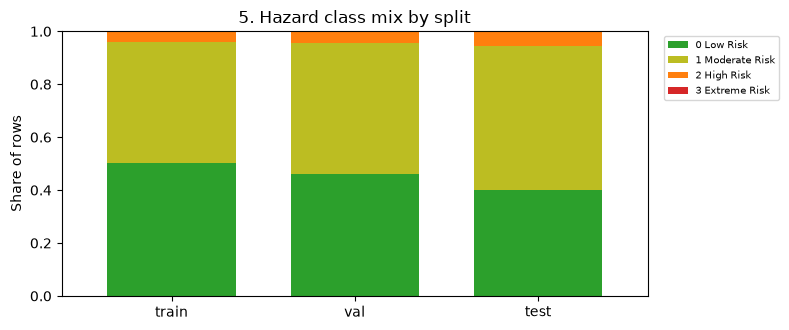

In [31]:
class_mix = pd.DataFrame({
    name: frame[WHC_TARGET_COLUMN].value_counts().reindex(list(WHC_LABELS)).fillna(0).astype(int)
    for name, frame in whc_splits.items()
})
class_mix.index = pd.Index([f"{c} {WHC_LABELS[c]}" for c in class_mix.index], name="class")
class_share = class_mix / class_mix.sum()

print("Hazard class counts by split:")
print(class_mix.to_string())
print("\nHazard class shares by split:")
print(class_share.to_string(float_format="{:.2%}".format))

problems = []
for split_name in class_mix.columns:
    for class_name in class_mix.index:
        count = class_mix.loc[class_name, split_name]
        if count == 0 and class_mix.loc[class_name].sum() > 0:
            problems.append(f"'{class_name}' has no rows in the {split_name} split")
        elif 0 < count < 10:
            problems.append(f"'{class_name}' has only {count} row(s) in the {split_name} split")
never_observed = [c for c in class_mix.index if class_mix.loc[c].sum() == 0]

print()
if never_observed:
    print(f"NOTE: {never_observed} never occur anywhere in the modelling window. "
          "The classifier\n      can only learn the classes that are present; report this "
          "explicitly and consider\n      whether a 4-class metric is meaningful here.")
for problem in problems:
    print(f"WARNING: {problem}. Per-class recall will be undefined or unstable; prefer "
          "balanced\n         accuracy or a macro F1 restricted to observed classes, and "
          "report the confusion matrix.")
if not problems and not never_observed:
    print("All four hazard classes are represented in every split.")

fig, axis = plt.subplots(figsize=(8, 3.4))
class_share.T.plot.bar(stacked=True, ax=axis, width=0.7,
                       color=["tab:green", "tab:olive", "tab:orange", "tab:red"])
axis.set(title="5. Hazard class mix by split", ylabel="Share of rows", xlabel="")
axis.tick_params(labelrotation=0)
axis.legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
save_figure(fig, "splits-class-mix", subdir="weather_hazard")
plt.show()

## 6. Leakage verification and baselines

The guarantee that no feature depends on the future is checked empirically rather than asserted.
Features are rebuilt from a series **truncated at a sample date**, and the resulting row is
compared against the same row built from the full series. If any feature looked ahead, the two
would differ, because the truncated series has no future to look at.

This is the test that would catch an accidental `center=True`, a negative shift, or a
full-series transformation such as a global mean fill. Because the feature matrix is shared, one
run of this test covers both tasks.

Two further checks follow. The **target separation check** confirms that no column in the feature
matrix is the target in disguise, by looking for any feature perfectly correlated with a target
column. The **baselines** establish the floor each model must clear: a model that cannot beat
persistence or climatology is not adding value regardless of its absolute score.

In [32]:
rng = np.random.default_rng(0)
candidate_dates = features.index[features.index > features.index.min() +
                                 pd.Timedelta(days=WARMUP_DAYS)]
sample_dates = pd.DatetimeIndex(
    rng.choice(candidate_dates, size=min(25, len(candidate_dates)), replace=False)
).sort_values()

mismatches: list[str] = []
for date in sample_dates:
    truncated, _ = build_features(daily.loc[:date])
    full_row = features.loc[date]
    truncated_row = truncated.loc[date]
    differing = full_row.index[~np.isclose(full_row.to_numpy(dtype=float),
                                           truncated_row.to_numpy(dtype=float),
                                           equal_nan=True)]
    mismatches.extend(f"{date:%Y-%m-%d}: {column}" for column in differing)

if mismatches:
    raise AssertionError(
        f"{len(mismatches)} feature value(s) changed when future data was removed, "
        f"indicating leakage. Examples: {mismatches[:5]}"
    )
print(f"No leakage detected across {len(sample_dates)} sampled dates "
      f"x {len(FEATURE_COLUMNS)} features.")

# No feature may be a target in disguise.
suspicious = []
for target in CCI_TARGET_COLUMNS:
    correlations = cci_dataset[FEATURE_COLUMNS].corrwith(cci_dataset[target]).abs()
    suspicious += [f"{column} vs {target} (|r|={correlations[column]:.4f})"
                   for column in correlations.index[correlations > 0.999]]
hazard_correlations = (
    whc_dataset[FEATURE_COLUMNS].corrwith(whc_dataset[WHC_AUXILIARY_COLUMN]).abs()
)
suspicious += [f"{column} vs {WHC_AUXILIARY_COLUMN} (|r|={hazard_correlations[column]:.4f})"
               for column in hazard_correlations.index[hazard_correlations > 0.999]]
if suspicious:
    raise AssertionError(f"Feature(s) effectively identical to a target: {suspicious}")
print("Target separation verified: no feature is perfectly correlated with any target.")

No leakage detected across 25 sampled dates x 105 features.
Target separation verified: no feature is perfectly correlated with any target.


In [33]:
train_cci = cci_splits["train"]
persistence = pd.DataFrame(
    {
        "corr_cci_t_vs_target": [train_cci["cci"].corr(train_cci[f"cci_t{h}"])
                                 for h in CCI_HORIZONS],
        "persistence_mae": [(train_cci[f"cci_t{h}"] - train_cci["cci"]).abs().mean()
                            for h in CCI_HORIZONS],
        "climatology_mae": [
            (train_cci[f"cci_t{h}"] -
             train_cci.index.dayofyear.map(train_cci.groupby(train_cci.index.dayofyear)["cci"]
                                           .mean())).abs().mean()
            for h in CCI_HORIZONS
        ],
        "target_sd": [train_cci[f"cci_t{h}"].std() for h in CCI_HORIZONS],
    },
    index=pd.Index(CCI_HORIZONS, name="horizon_days"),
)
print("Comfort baselines on the training split - the floor the regressors must clear:")
print(persistence.to_string())

train_whc = whc_splits["train"]
majority_class = int(train_whc[WHC_TARGET_COLUMN].mode().iloc[0])
majority_accuracy = (train_whc[WHC_TARGET_COLUMN] == majority_class).mean()

# The class on day t is not itself a feature, but it follows directly from the `whi` feature by
# applying the brief's thresholds, so the persistence rule is available without extra inputs.
class_at_t = np.digitize(train_whc["whi"].to_numpy(dtype=float), bins=[25, 50, 75], right=False)
persistence_accuracy = (train_whc[WHC_TARGET_COLUMN].to_numpy() == class_at_t).mean()
seasonal_mode = train_whc.groupby(train_whc.index.month)[WHC_TARGET_COLUMN].agg(
    lambda s: s.mode().iloc[0]
)
seasonal_accuracy = (
    train_whc[WHC_TARGET_COLUMN] == train_whc.index.month.map(seasonal_mode)
).mean()

print("\nHazard baselines on the training split - the floor the classifier must clear:")
hazard_baselines = pd.Series({
    f"majority class ({WHC_LABELS[majority_class]})": majority_accuracy,
    f"persistence (class at t carried to t+{WHC_HORIZON})": persistence_accuracy,
    "monthly modal class": seasonal_accuracy,
}, name="accuracy")
print(hazard_baselines.to_string(float_format="{:.3f}".format))
print(f"\n  Balanced accuracy of the majority-class rule is "
      f"{1 / train_whc[WHC_TARGET_COLUMN].nunique():.3f} by construction, which is why "
      "accuracy alone\n  is not an adequate metric for this target.")

Comfort baselines on the training split - the floor the regressors must clear:
              corr_cci_t_vs_target  persistence_mae  climatology_mae  target_sd
horizon_days                                                                   
1                             0.59             6.93             7.37      10.26
2                             0.37             8.81             7.59      10.26
3                             0.27             9.52             7.69      10.26

Hazard baselines on the training split - the floor the classifier must clear:
majority class (Low Risk)                 0.503
persistence (class at t carried to t+7)   0.481
monthly modal class                       0.563

  Balanced accuracy of the majority-class rule is 0.250 by construction, which is why accuracy alone
  is not an adequate metric for this target.


## 7. Outputs

Features and targets are written to **separate files**. Each split produces an `X_*.csv` holding
only the shared feature columns and a `y_*.csv` holding only that task's targets, both indexed by
`feature_date`.

The separation is a safeguard as much as a convention. With one combined file, every load has to
remember to drop the target columns before fitting, and a single `drop` that misses a column is
silent leakage which will not surface until a test score looks implausibly good. Splitting the
files makes that mistake impossible to make by accident: the feature file simply does not contain
a label. It also lets the API validate an incoming request against `X_train.csv` directly,
without needing to know which columns to strip.

For the hazard task the continuous `whi_t7` goes to a third file, `aux_*.csv`, rather than sitting
beside the label in `y_*.csv`. It is the label in continuous form, so keeping it out of both `X`
and `y` means it can only reach a model if someone loads it deliberately.

`X` and `y` are aligned by the `feature_date` index, never by row order. That is checked after
writing by reloading both files and comparing indices, which would also catch a partial write or
a stale file left behind from an earlier run.

The `feature_columns` list is identical in both metadata files by construction, which is the
property the API depends on: one feature-building routine serves both endpoints.

In [34]:
def write_splits(splits: dict[str, pd.DataFrame], directory: Path, target_columns: list[str],
                 auxiliary_columns: list[str] | None = None) -> dict[str, int]:
    """Write each split as separate feature, target and auxiliary files.

    Parameters
    ----------
    splits
        Mapping of split name to the combined feature-and-target frame.
    directory
        Destination directory for this task.
    target_columns
        Columns written to ``y_{split}.csv``. ``FEATURE_COLUMNS`` is written to ``X_{split}.csv``.
    auxiliary_columns
        Optional columns written to ``aux_{split}.csv``. These are neither features nor labels
        and must not be passed to a model.

    Returns
    -------
    dict
        Rows written per split.
    """
    directory.mkdir(parents=True, exist_ok=True)
    blocks = {"X": FEATURE_COLUMNS, "y": target_columns}
    if auxiliary_columns:
        blocks["aux"] = auxiliary_columns

    written = {}
    for name, frame in splits.items():
        described = []
        for prefix, columns in blocks.items():
            path = directory / f"{prefix}_{name}.csv"
            frame[columns].to_csv(path, index_label="feature_date")
            described.append(f"{path.name} [{len(columns)} col]")
        written[name] = len(frame)
        print(f"  {name:<5} {len(frame):>6,} rows -> {', '.join(described)}")
    return written


def verify_written_splits(directory: Path, splits: dict[str, pd.DataFrame],
                          target_columns: list[str], label: str) -> None:
    """Reload the written files and confirm X and y still line up row for row."""
    for name in splits:
        reloaded_x = pd.read_csv(directory / f"X_{name}.csv", index_col="feature_date",
                                 parse_dates=["feature_date"])
        reloaded_y = pd.read_csv(directory / f"y_{name}.csv", index_col="feature_date",
                                 parse_dates=["feature_date"])
        if not reloaded_x.index.equals(reloaded_y.index):
            raise AssertionError(f"{label}/{name}: X and y indices do not match after writing.")
        if list(reloaded_x.columns) != FEATURE_COLUMNS:
            raise AssertionError(f"{label}/{name}: X columns changed on the round trip.")
        if list(reloaded_y.columns) != target_columns:
            raise AssertionError(f"{label}/{name}: y columns changed on the round trip.")
        if set(reloaded_x.columns) & set(reloaded_y.columns):
            raise AssertionError(f"{label}/{name}: a target column leaked into the feature file.")
    print(f"  {label}: X/y alignment and column separation verified on reload.")


shared_metadata = {
    "student_id": "25945320",
    "location": {"city": "Sydney, NSW, Australia", "latitude": -33.8688, "longitude": 151.2093},
    "source": "Open-Meteo Historical Weather API",
    "feature_columns": FEATURE_COLUMNS,
    "feature_groups": FEATURE_GROUPS,
    "daily_aggregations": aggregations,
    "excluded_constant_columns": ZERO_VARIANCE_COLUMNS,
    "snowfall_observed": bool(SNOWFALL_OBSERVED),
    "warmup_days": int(WARMUP_DAYS),
    "file_layout": {
        "features": "X_{split}.csv",
        "targets": "y_{split}.csv",
        "index": "feature_date",
        "note": "X and y are aligned by the feature_date index, not by row order.",
    },
    "split_boundaries": {
        "val_start": VAL_START.strftime("%Y-%m-%d"),
        "test_start": TEST_START.strftime("%Y-%m-%d"),
        "production_cutoff": PRODUCTION_CUTOFF.strftime("%Y-%m-%d"),
    },
}

print("Comfort (CCI):")
cci_rows = write_splits(cci_splits, PROCESSED_DIRS["comfort_climate"], CCI_TARGET_COLUMNS)
cci_metadata = {
    **shared_metadata,
    "target": "Climate Comfort Index",
    "prediction_type": "regression",
    "horizons_days": list(CCI_HORIZONS),
    "target_columns": CCI_TARGET_COLUMNS,
    "embargo_days": int(CCI_EMBARGO),
    "split_rows": {k: int(v) for k, v in cci_rows.items()},
    "baselines_train": {
        f"persistence_mae_t{h}": float(persistence.loc[h, "persistence_mae"])
        for h in CCI_HORIZONS
    },
}
cci_metadata_path = PROCESSED_DIRS["comfort_climate"] / "cci_feature_metadata.json"
cci_metadata_path.write_text(json.dumps(cci_metadata, indent=2))
print(f"  metadata    -> {cci_metadata_path.name}")

print("\nHazard (WHC):")
whc_rows = write_splits(whc_splits, PROCESSED_DIRS["weather_hazard"], [WHC_TARGET_COLUMN],
                        [WHC_AUXILIARY_COLUMN])
whc_metadata = {
    **shared_metadata,
    "target": "Weather Hazard Category",
    "prediction_type": "multiclass_classification",
    "horizons_days": [int(WHC_HORIZON)],
    "target_columns": [WHC_TARGET_COLUMN],
    "auxiliary_columns": [WHC_AUXILIARY_COLUMN],
    "auxiliary_file": "aux_{split}.csv",
    "auxiliary_note": (
        f"{WHC_AUXILIARY_COLUMN} is the continuous index behind the label. It is provided for "
        "error analysis only and must be dropped before fitting."
    ),
    "class_labels": {str(k): v for k, v in WHC_LABELS.items()},
    "class_counts_by_split": {
        name: {str(c): int(frame[WHC_TARGET_COLUMN].value_counts().get(c, 0))
               for c in WHC_LABELS}
        for name, frame in whc_splits.items()
    },
    "embargo_days": int(WHC_EMBARGO),
    "split_rows": {k: int(v) for k, v in whc_rows.items()},
    "baselines_train": {
        "majority_class": int(majority_class),
        "majority_class_accuracy": float(majority_accuracy),
        "persistence_accuracy": float(persistence_accuracy),
        "monthly_mode_accuracy": float(seasonal_accuracy),
    },
}
whc_metadata_path = PROCESSED_DIRS["weather_hazard"] / "whc_feature_metadata.json"
whc_metadata_path.write_text(json.dumps(whc_metadata, indent=2))
print(f"  metadata    -> {whc_metadata_path.name}")

verify_written_splits(PROCESSED_DIRS["comfort_climate"], cci_splits, CCI_TARGET_COLUMNS,
                      "Comfort (CCI)")
verify_written_splits(PROCESSED_DIRS["weather_hazard"], whc_splits, [WHC_TARGET_COLUMN],
                      "Hazard (WHC)")

if cci_metadata["feature_columns"] != whc_metadata["feature_columns"]:
    raise AssertionError("The two datasets no longer share an identical feature matrix.")
print(f"\nBoth datasets share the same {len(FEATURE_COLUMNS)} feature columns in the same order.")

Comfort (CCI):
  train  2,889 rows -> X_train.csv [105 col], y_train.csv [3 col]
  val      363 rows -> X_val.csv [105 col], y_val.csv [3 col]
  test     362 rows -> X_test.csv [105 col], y_test.csv [3 col]
  metadata    -> cci_feature_metadata.json

Hazard (WHC):
  train  2,885 rows -> X_train.csv [105 col], y_train.csv [1 col], aux_train.csv [1 col]
  val      359 rows -> X_val.csv [105 col], y_val.csv [1 col], aux_val.csv [1 col]
  test     358 rows -> X_test.csv [105 col], y_test.csv [1 col], aux_test.csv [1 col]
  metadata    -> whc_feature_metadata.json
  Comfort (CCI): X/y alignment and column separation verified on reload.
  Hazard (WHC): X/y alignment and column separation verified on reload.

Both datasets share the same 105 feature columns in the same order.


### Output contract

| File | Rows | Columns |
| --- | --- | --- |
| `data/interim/sydney_daily.csv` | full archive, incl. reserved 2026+ | Daily aggregates, component scores, both indices. Auditing artefact for the aggregation and target-construction steps. |
| `data/processed/comfort_climate/X_{train,val,test}.csv` | archive start to 2023 less 3-day embargo / 2024 / 2025 | The 105 shared features, indexed by `feature_date`. |
| `data/processed/comfort_climate/y_{train,val,test}.csv` | matching `X_*` row for row | `cci_t1`, `cci_t2`, `cci_t3`. |
| `data/processed/comfort_climate/cci_feature_metadata.json` | — | Feature families and columns, target names, aggregation rules, split boundaries, 3-day embargo, training baselines. |
| `data/processed/weather_hazard/X_{train,val,test}.csv` | archive start to 2023 less 7-day embargo / 2024 / 2025 | The same 105 features, same order. |
| `data/processed/weather_hazard/y_{train,val,test}.csv` | matching `X_*` row for row | `whc_t7` only. |
| `data/processed/weather_hazard/aux_{train,val,test}.csv` | matching `X_*` row for row | `whi_t7`, for error analysis only. Never a feature, never a label. |
| `data/processed/weather_hazard/whc_feature_metadata.json` | — | As for comfort, plus class labels, per-split class counts and the auxiliary-column warning. |

The comfort and hazard `X_*` files share the same columns in the same order but **not** the same
rows: the 7-day horizon and its wider embargo cost the hazard task a few days at the end of each
period. Do not assume a row in one lines up with the same row in the other.

**Loading pattern for both modelling notebooks**

```python
def load_split(directory, name):
    read = lambda prefix: pd.read_csv(
        directory / f"{prefix}_{name}.csv", index_col="feature_date", parse_dates=["feature_date"]
    )
    X, y = read("X"), read("y")
    assert X.index.equals(y.index)      # alignment is by date, not by position
    return X, y
```

**For the comfort modelling notebook** (`notebooks/comfort_climate/`)

- Load the three splits as-is; do not re-split or shuffle.
- `y` has three columns. Fit one model per horizon against the same `X`, so the cross-horizon
  comparison is like for like.
- Fit scalers and any imputation on `train` only.
- Use `val` for model selection and hyperparameter search; touch `test` once, at the end.
- Report metrics per horizon rather than averaged — skill is expected to decay with lead time.
- Run the family ablation using `feature_groups` from the metadata file, so the contribution of
  each engineered family is measured rather than assumed.
- Baselines to beat, printed in section 6: persistence (predict `cci` at *t*, which is a column
  of `X`) and climatology (the seasonal day-of-year mean from the training split).

**For the hazard modelling notebook** (`notebooks/weather_hazard/`)

- `y_*.csv` contains only `whc_t7`, so there is nothing to drop before fitting. Load `aux_*.csv`
  separately, and only for error analysis.
- Do not stratify or shuffle: the chronological order is the point of the split.
- Accuracy is not sufficient given the class imbalance reported in section 5. Report balanced
  accuracy or macro F1 alongside a confusion matrix, and state explicitly which classes are
  present in each split.
- Class weighting or resampling is a modelling decision left to that notebook; the imbalance is
  documented here so the choice can be justified rather than defaulted.
- Use `whi_t7` from `aux_*.csv` to separate near-boundary errors from substantive ones. A day at
  WHI 24.8 predicted Moderate is a different failure from one at WHI 12.
- Baselines to beat, printed in section 6: the majority class, the +7 day persistence rule and
  the monthly modal class.

**For the API repository**

- `build_features`, `calculate_cci` and `calculate_whc` are the code the service must reproduce.
  Move them into the custom package rather than copying them, so the serving path and the
  training path cannot diverge.
- Validate an incoming feature vector against `feature_columns` from the metadata file, in order.
  The header of any `X_*.csv` is the same contract if the metadata is unavailable.
- Serving a single prediction needs 30 days of history before the requested date, per the
  warm-up in section 3.